In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


In [1]:
'''from circuits.templates import IQPAnsatz , AngleAnsatz
from circuits.constructor import CircuitBuilder
from feature_maps.templates import AngleEmbedding, NeuralEmbedding
from rl.policies import PQCBorn, PQCSoftmax
#from rl.torchrl import TorchRLTrainer , REINFORCE
from rl.metrics import policy_variance
from pennylane import numpy as np
from rl.model import create_model, draw_model
import pennylane as qml
import torch
from rl.torchrl import REINFORCE, BanditAWRConfig , ContextualBanditTrainer
'''

import torch
from qasp import * 

['Y 0', 'Y 1', 'Y 2', 'Y 3', 'Z 0', 'Z 1', 'Z 2', 'Z 3', 'Y 0', 'Y 1', 'Y 2', 'Y 3', 'YY 0 1', 'YY 0 2', 'YY 0 3', 'YY 1 2', 'YY 1 3', 'YY 2 3']
(18,)


(<Figure size 1300x500 with 1 Axes>, <Axes: >)

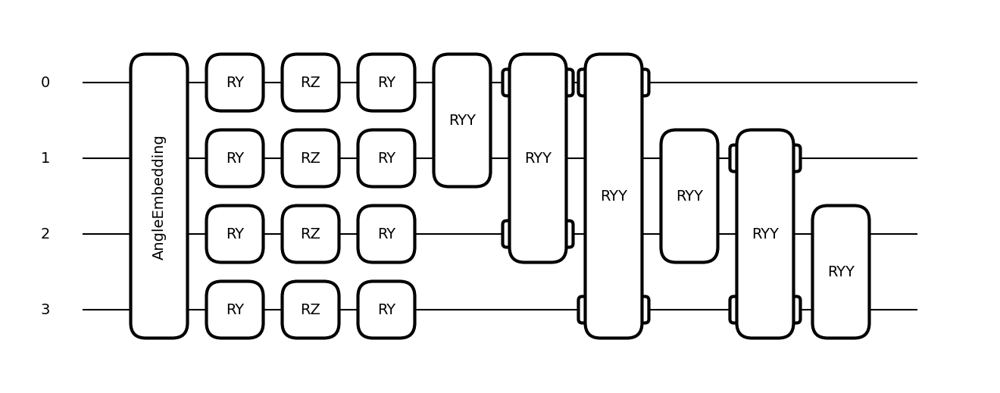

In [2]:

#fm = AngleEmbedding(features=4, n_qubits=4, rotations="Z", input_scaling=True)
fm = AngleEmbedding(features=4, n_qubits=4, rotations="Y" , input_scaling=False)

#iqp = IQPAnsatz(n_qubits=4, pattern="ring", n_layers=1, feature_map=fm, reuploading=True)
n_qubits = 4
rotations = ["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)]+["YY {} {}".format(i, j) for i in range(n_qubits-1) for j in range(i+1, n_qubits)]
print(rotations)
ansatz = AngleAnsatz(n_qubits=4, n_layers=1 , rotations = rotations , feature_map=fm , include_imprimitive=False, imprimitive = "CNOT" , imprimitive_pattern="all_to_all", reuploading=False)

# 2. Query the parameter shapes so you know how to init your params
shapes = ansatz.get_param_shapes()

# Create a params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]  
) 

# Create a params array matching that shape

print(params.shape)

# 3. Build your circuit
builder = CircuitBuilder(n_qubits=4)
builder.set_ansatz(ansatz)           # pass the IQPAnsatz instance


qml.draw_mpl(builder.ansatz, show_all_wires=True, show_all_operations=True)(inputs=np.random.random(4),params=params)

In [5]:

fm_config = {
    "features": lambda n: n,
    "rotations": "Y",
    "input_scaling": False
}

ansatz_config = {
    "n_layers": lambda n: 1,
    "rotations" : lambda n: ["Y {}".format(i) for i in range(n)]+["Z {}".format(i) for i in range(n)]+["Y {}".format(i) for i in range(n)]+["YY {} {}".format(i, (i+1)%n) for i in range(n)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": lambda n: 4,
    "init": "uniform_-pi_pi",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False
}

variance_qubit = policy_variance(policy_class="PQCBorn", 
                            policy_config_kwargs=policy_model_config,
                            n_samples=5000,
                            action=None,
                            qubit_list=[4,6,8,10,12],
                            parallel=True
)

KeyboardInterrupt: 

In [ ]:
print(variance_qubit)

[np.float64(0.008418792179154474), np.float64(0.005296976964119787), np.float64(0.00960252256597898), np.float64(0.008352741086073798), np.float64(0.0023120476327177946), np.float64(0.010537887271107969), np.float64(0.010490705892677374)]


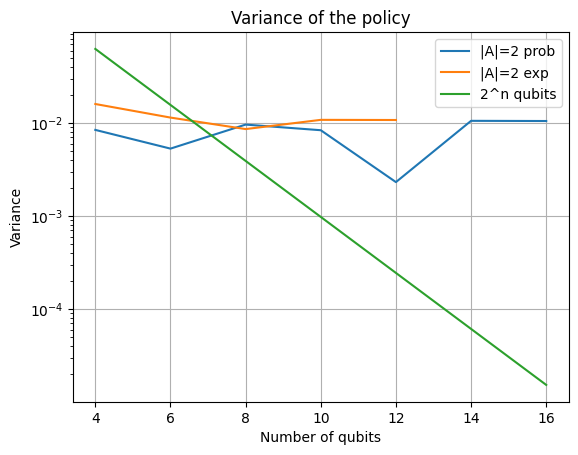

In [ ]:
import matplotlib.pyplot as plt

qubit_list = [4,6,8,10,12,14,16]
qubit_list_b = [4,6,8,10,12]
plt.plot(qubit_list, [np.float64(0.008418792179154474), np.float64(0.005296976964119787), np.float64(0.00960252256597898), np.float64(0.008352741086073798), np.float64(0.0023120476327177946), np.float64(0.010537887271107969), np.float64(0.010490705892677374)], label="|A|=2 prob")
plt.plot(qubit_list_b, variance_qubit, label="|A|=2 exp")
plt.plot(qubit_list, [2**(-i) for i in qubit_list], label="2^n qubits")
#plt.plot(qubit_list, [(1/16)*((0.25**i) + 0.25**(i-1) + 0.25) for i in qubit_list], label="theory LB")
#plt.plot(qubit_list, [(1/16)*((0.5**i) + 0.5**(i-1) + 0.5) for i in qubit_list], label="theory UP")
#plt.plot(qubit_list, [(1/4)*(0.5**(i/2)) for i in qubit_list], label="theory exp")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")

plt.yscale("log")

plt.title("Variance of the policy")
plt.grid()

plt.legend()

plt.show()


In [ ]:
#save variances in numpy format in folder 'data_variance_born_paper'

np.save("data_variance_born_paper/variances_YY_ring_a=4_parity_like.npy", variance_qubit)

## reward function r=a |A|=4

In [ ]:
n_qubits = 16
fm_config = {
    "features": n_qubits,
    "rotations": "Y",
    "input_scaling": False
}

ansatz_config = {
    "n_layers": 1,
    "rotations": ["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)]+["YY {} {}".format(i, (i+1)) for i in range(n_qubits-1)],#for j in range(i+1, n_qubits)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    #"init": "ones",
    "init": "random_-pi_pi",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "adjoint",
    #"diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    #"training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [i for i in range(0,n_qubits,int(np.ceil(n_qubits/(np.log2(n_qubits)**1.5))))]
}


In [ ]:

policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)

Using specified device: lightning.kokkos


In [ ]:
policy1.forward(torch.zeros(n_qubits))

tensor([0.0449, 0.4551, 0.4551, 0.0449], grad_fn=<CopySlices>)

In [ ]:
n_qubits = 16
fm_config = {
    "features": n_qubits,
    "rotations": "Y",
    "input_scaling": False
}

ansatz_config = {
    "n_layers": 1,
    "rotations": ["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)]+["YY {} {}".format(i, (i+1)) for i in range(n_qubits-1)],#for j in range(i+1, n_qubits)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "random_-pi_pi",
    #"init": "ones",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [i for i in range(0,n_qubits,int(np.ceil(n_qubits/(np.log2(n_qubits)**1.5))))]
}

policy2 = create_model("PQCBorn", policy_model_config, n_qubits=16)
policy2.qlayer.load_state_dict(policy1.qlayer.state_dict())
policy2.forward(torch.zeros(n_qubits))

Using specified device: lightning.kokkos


tensor([0.0449, 0.4551, 0.4551, 0.0449], grad_fn=<ToCopyBackward0>)

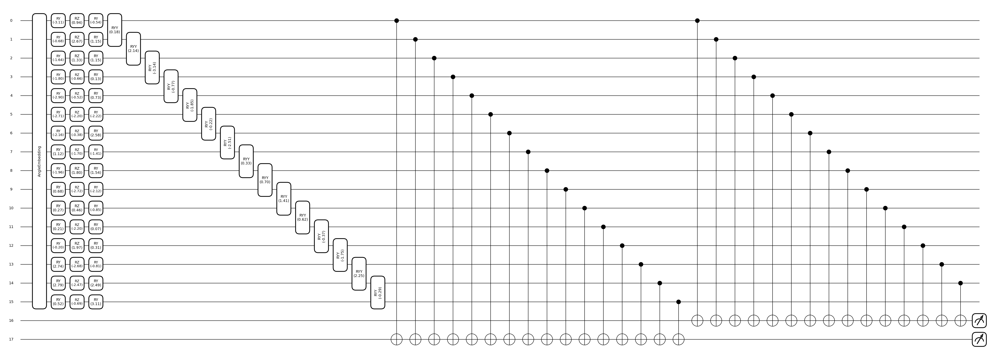

In [ ]:

fig, ax = draw_model(model=policy1,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(n_qubits))

In [ ]:
policy1.qlayer.state_dict()["params"]

tensor([ 0.4633, -1.5610, -1.4509,  0.9345,  3.1081, -1.0741,  2.4144,  1.1620,
        -1.6536, -1.0743,  0.4861,  0.1731, -2.6913, -2.8367,  2.6323,  1.8802,
        -2.3070, -0.7851,  2.4017, -1.7437, -2.6496, -2.1191,  0.2983,  1.4934,
         2.4595,  0.0846,  0.8250, -2.9992,  2.1587,  1.2685,  1.7037,  1.0916,
         2.6710,  0.2917,  1.4073, -3.1144, -2.3437,  1.8739,  0.7625, -0.7901,
        -2.2193, -2.2463,  3.0718,  2.0217, -1.3759, -0.3963,  2.5934, -1.2401,
        -1.2163,  0.4928,  2.8738,  1.1757,  0.7624,  1.3565,  1.3709,  1.0676,
        -0.1635,  2.1136, -1.6504, -1.2401, -2.2519,  3.1327, -0.6743])

In [ ]:
state = torch.zeros(n_qubits)

optimizer = torch.optim.Adam(policy1.parameters(), lr=0.1)

#train policy to maximize probability of action 3 for 100 steps:
#reward = 3 if action == 3 else -1
#save probabilities of action 3
#probs_action_3 = []
#print( qml.specs(policy1.circuit)(inputs=state , params = policy1.get_weights()["params"]))
print(policy1.diff_method)
rewards = []
for i in range(100):
    action_probs = policy1.forward(state)
    loss = - torch.log(action_probs[3])
    print(action_probs)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()




adjoint
tensor([0.0449, 0.4551, 0.4551, 0.0449], grad_fn=<CopySlices>)
tensor([0.0856, 0.4144, 0.4144, 0.0856], grad_fn=<CopySlices>)
tensor([0.1400, 0.3600, 0.3600, 0.1400], grad_fn=<CopySlices>)
tensor([0.2045, 0.2955, 0.2955, 0.2045], grad_fn=<CopySlices>)
tensor([0.2735, 0.2265, 0.2265, 0.2735], grad_fn=<CopySlices>)
tensor([0.3402, 0.1598, 0.1598, 0.3402], grad_fn=<CopySlices>)
tensor([0.3984, 0.1016, 0.1015, 0.3985], grad_fn=<CopySlices>)
tensor([0.4430, 0.0569, 0.0565, 0.4436], grad_fn=<CopySlices>)
tensor([0.4713, 0.0278, 0.0271, 0.4738], grad_fn=<CopySlices>)
tensor([0.4835, 0.0133, 0.0131, 0.4901], grad_fn=<CopySlices>)
tensor([0.4827, 0.0101, 0.0126, 0.4946], grad_fn=<CopySlices>)
tensor([0.4752, 0.0142, 0.0216, 0.4890], grad_fn=<CopySlices>)
tensor([0.4675, 0.0229, 0.0349, 0.4747], grad_fn=<CopySlices>)
tensor([0.4605, 0.0344, 0.0475, 0.4577], grad_fn=<CopySlices>)
tensor([0.4517, 0.0465, 0.0570, 0.4448], grad_fn=<CopySlices>)
tensor([0.4415, 0.0567, 0.0636, 0.4382], grad_f

KeyboardInterrupt: 

In [ ]:
state = torch.zeros(n_qubits)


optimizer = torch.optim.Adam(policy2.parameters(), lr=0.1)

#train policy to maximize probability of action 3 for 100 steps:
#reward = 3 if action == 3 else -1
#save probabilities of action 3
#probs_action_3 = []
rewards = []
for i in range(30):
    action_probs = policy2.forward(state)
    loss = - torch.log(action_probs[7])
    print(action_probs)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()




tensor([0.0914, 0.2529, 0.0969, 0.0588, 0.0588, 0.0969, 0.2529, 0.0914],
       grad_fn=<ToCopyBackward0>)
tensor([0.1292, 0.1966, 0.0975, 0.0767, 0.0767, 0.0975, 0.1965, 0.1292],
       grad_fn=<ToCopyBackward0>)
tensor([0.1666, 0.1690, 0.0743, 0.0901, 0.0901, 0.0743, 0.1690, 0.1666],
       grad_fn=<ToCopyBackward0>)
tensor([0.1998, 0.1547, 0.0470, 0.0985, 0.0985, 0.0470, 0.1547, 0.1998],
       grad_fn=<ToCopyBackward0>)
tensor([0.2264, 0.1513, 0.0221, 0.1002, 0.1002, 0.0221, 0.1513, 0.2264],
       grad_fn=<ToCopyBackward0>)
tensor([0.2457, 0.1539, 0.0065, 0.0940, 0.0940, 0.0065, 0.1539, 0.2457],
       grad_fn=<ToCopyBackward0>)
tensor([0.2580, 0.1571, 0.0044, 0.0805, 0.0805, 0.0044, 0.1571, 0.2580],
       grad_fn=<ToCopyBackward0>)
tensor([0.2643, 0.1573, 0.0158, 0.0626, 0.0626, 0.0158, 0.1573, 0.2643],
       grad_fn=<ToCopyBackward0>)
tensor([0.2664, 0.1528, 0.0368, 0.0440, 0.0440, 0.0368, 0.1528, 0.2664],
       grad_fn=<ToCopyBackward0>)
tensor([0.2666, 0.1435, 0.0618, 0.028

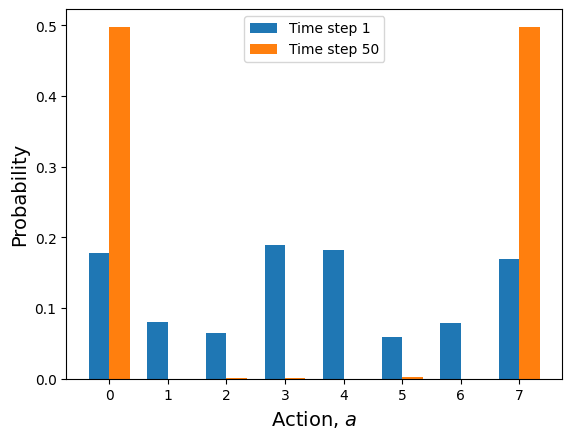

In [ ]:
#plot bars side by side for time step 1 and time step 50
#Visualize the probability histogram
import matplotlib.pyplot as plt
probs_t1 = [0.1772, 0.0803, 0.0642, 0.1895, 0.1826, 0.0583, 0.0791, 0.1687]
probs_t50 = [4.9780e-01, 2.4414e-04, 1.7090e-03, 4.8828e-04, 2.4414e-04, 1.9531e-03,
        2.4414e-04, 4.9731e-01]
probs_t50_hidden = [4.3945e-03, 2.4414e-04, 0.0000e+00, 9.7656e-04, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 9.9438e-01]
x = np.arange(len(probs_t1))
width = 0.35
labels = [i for i in range(len(probs_t1))]

plt.bar(x - width/2, probs_t1, width=width, label="Time step 1")
plt.bar(x + width/2, probs_t50, width=width, label="Time step 50")
plt.xticks(x, labels)
plt.legend()


plt.xlabel(r"Action, $a$", fontsize=14)
plt.ylabel("Probability", fontsize=14)
#plt.title("Probability Distribution")

#dpi to 300 
plt.savefig("data_variance_born_paper/parity_global_policy_probability_distribution.png", dpi=300)


### NEW 3-local model

['Y 0', 'Y 1', 'Y 2', 'Y 3', 'Y 4', 'Y 5', 'Y 6', 'Y 7', 'Y 8', 'Y 9', 'Y 10', 'Y 11', 'Y 12', 'Y 13', 'Y 14', 'Y 15', 'Y 16', 'Y 17', 'Y 18', 'Y 19', 'Z 0', 'Z 1', 'Z 2', 'Z 3', 'Z 4', 'Z 5', 'Z 6', 'Z 7', 'Z 8', 'Z 9', 'Z 10', 'Z 11', 'Z 12', 'Z 13', 'Z 14', 'Z 15', 'Z 16', 'Z 17', 'Z 18', 'Z 19', 'Y 0', 'Y 1', 'Y 2', 'Y 3', 'Y 4', 'Y 5', 'Y 6', 'Y 7', 'Y 8', 'Y 9', 'Y 10', 'Y 11', 'Y 12', 'Y 13', 'Y 14', 'Y 15', 'Y 16', 'Y 17', 'Y 18', 'Y 19', 'YY 0 1', 'YY 2 3', 'YY 4 5', 'YY 6 7', 'YY 8 9', 'YY 10 11', 'YY 12 13', 'YY 14 15', 'YY 16 17', 'YY 18 19', 'YYY 2 3 4', 'YYY 5 6 7', 'YYY 8 9 10', 'YYY 11 12 13', 'YYY 14 15 16', 'YYY 17 18 19']
(76,)


(<Figure size 900x2100 with 1 Axes>, <Axes: >)

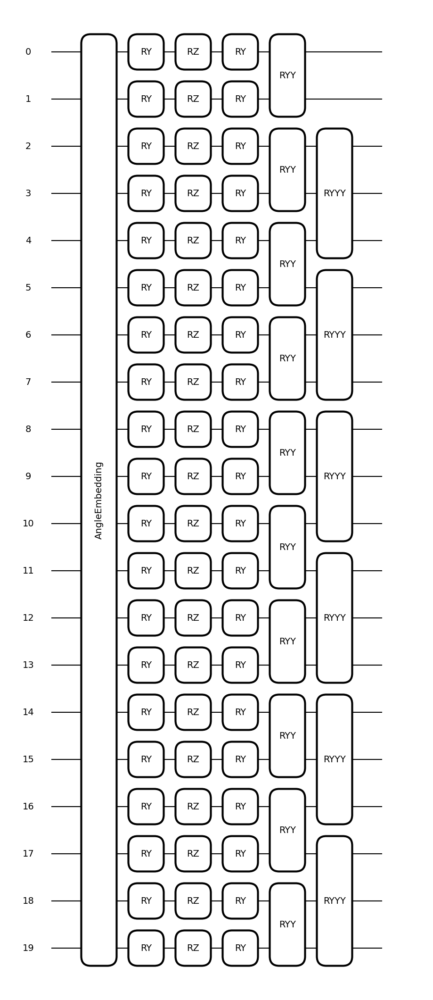

In [ ]:

#fm = AngleEmbedding(features=4, n_qubits=4, rotations="Z", input_scaling=True)
n_qubits = 20

fm = AngleEmbedding(features=n_qubits, n_qubits=n_qubits, rotations="Y" , input_scaling=False)

#iqp = IQPAnsatz(n_qubits=4, pattern="ring", n_layers=1, feature_map=fm, reuploading=True)
rotations = ["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)]+["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(2,n_qubits-2,3)]
print(rotations)
ansatz = AngleAnsatz(n_qubits=n_qubits, n_layers=1 , rotations = rotations , feature_map=fm , include_imprimitive=False, imprimitive = "CNOT" , imprimitive_pattern="all_to_all", reuploading=False)

# 2. Query the parameter shapes so you know how to init your params
shapes = ansatz.get_param_shapes()

# Create a params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0]  
) 

# Create a params array matching that shape

print(params.shape)

# 3. Build your circuit
builder = CircuitBuilder(n_qubits=n_qubits)
builder.set_ansatz(ansatz)           # pass the IQPAnsatz instance


qml.draw_mpl(builder.ansatz, show_all_wires=True, show_all_operations=True)(inputs=np.random.random(n_qubits),params=params)

In [ ]:

fm_config = {
    "features": lambda n: n,
    "rotations": "Y",
    "input_scaling": False
}

ansatz_config = {
    "n_layers": lambda n: 1,
    "rotations" : lambda n: ["Y {}".format(i) for i in range(n)]+["Z {}".format(i) for i in range(n)]+["Y {}".format(i) for i in range(n)]+["YY {} {}".format(i, i+1) for i in range(0,n-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(2,n-2,3)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": lambda n: 5,
    "init": "uniform_-pi_pi",
    "policy": "hidden-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    "measurement_qubits": lambda n: [i for i in range(0,n,3)]
}

variance_qubit = policy_variance(policy_class="PQCBorn", 
                            policy_config_kwargs=policy_model_config,
                            n_samples=2500,
                            action=None,
                            qubit_list=[4,6,8,9,10,12,14,16,18,20],
                            parallel=True
)

2025-12-11 16:06:23,809	INFO worker.py:1888 -- Started a local Ray instance.


- Starting sampling for n_qubits: 4
(sampler pid=17425) measurement_qubits: [0, 3]
(sampler pid=17425) Using specified device: lightning.kokkos
- Starting sampling for n_qubits: 6
- Starting sampling for n_qubits: 8
(sampler pid=17424) measurement_qubits: [0, 3, 6] [repeated 12x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see https://docs.ray.io/en/master/ray-observability/user-guides/configure-logging.html#log-deduplication for more options.)
(sampler pid=17424) Using specified device: lightning.kokkos [repeated 12x across cluster]
- Starting sampling for n_qubits: 9
- Starting sampling for n_qubits: 10
(sampler pid=17424) measurement_qubits: [0, 3, 6, 9] [repeated 12x across cluster]
(sampler pid=17424) Using specified device: lightning.kokkos [repeated 12x across cluster]
- Starting sampling for n_qubits: 12
- Starting sampling for n_qubits: 14
(sampler pid=17424) measurement_qubits: [0, 3, 6, 9, 12] [repeated 12x across c

(sampler pid=17424) Using specified device: lightning.kokkos
(sampler pid=17424) measurement_qubits: [0, 3]
(sampler pid=17424) Using specified device: lightning.kokkos
(sampler pid=17424) measurement_qubits: [0, 3, 6] [repeated 12x across cluster]
(sampler pid=17424) Using specified device: lightning.kokkos [repeated 12x across cluster]
(sampler pid=17424) measurement_qubits: [0, 3, 6, 9] [repeated 12x across cluster]
(sampler pid=17424) Using specified device: lightning.kokkos [repeated 12x across cluster]
(sampler pid=17424) measurement_qubits: [0, 3, 6, 9, 12] [repeated 12x across cluster]
(sampler pid=17424) Using specified device: lightning.kokkos [repeated 12x across cluster]
(sampler pid=17424) measurement_qubits: [0, 3, 6, 9, 12, 15] [repeated 6x across cluster]
(sampler pid=17424) Using specified device: lightning.kokkos [repeated 6x across cluster]
(sampler pid=17424) measurement_qubits: [0, 3, 6, 9, 12, 15] [repeated 6x across cluster]
(sampler pid=17424) Using specified de

In [ ]:
[i for i in range(0,14,3)]

[0, 3, 6, 9, 12]

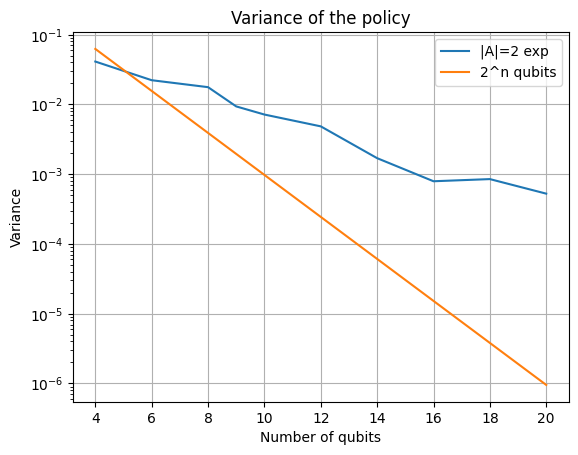

In [ ]:
import matplotlib.pyplot as plt

qubit_list = [4,6,8,9,10,12,14,16,18,20]
plt.plot(qubit_list, variance_qubit, label="|A|=2 exp")
plt.plot(qubit_list, [2**(-i) for i in qubit_list], label="2^n qubits")
#plt.plot(qubit_list, [(1/16)*((0.25**i) + 0.25**(i-1) + 0.25) for i in qubit_list], label="theory LB")
#plt.plot(qubit_list, [(1/16)*((0.5**i) + 0.5**(i-1) + 0.5) for i in qubit_list], label="theory UP")
#plt.plot(qubit_list, [(1/4)*(0.5**(i/2)) for i in qubit_list], label="theory exp")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")

plt.yscale("log")

plt.title("Variance of the policy")
plt.grid()

plt.legend()

plt.show()


In [ ]:
np.save("data_variance_born_paper/variances_YY_YYY_a=4_parity_like.npy", variance_qubit)

Using specified device: lightning.kokkos


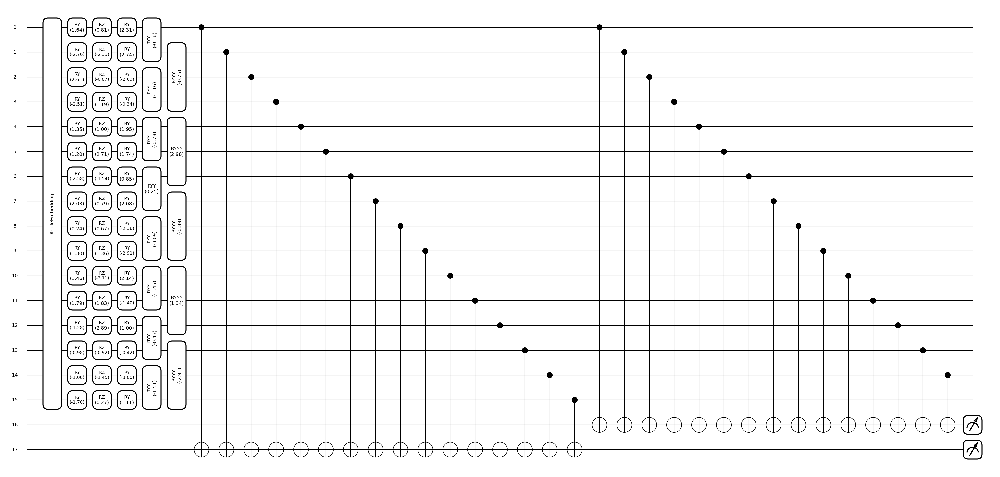

In [ ]:
n_qubits = 16
fm_config = {
    "features": n_qubits,
    "rotations": "Y",
    "input_scaling": False
}

ansatz_config = {
    "n_layers": 1,
    "rotations" : ["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)]+["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(1,n_qubits-2,3)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "random_-pi_pi",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [19,16,13,10,7,4,1]
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(model=policy1,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(n_qubits))

In [ ]:
np.log2(16)**1.3

np.float64(6.062866266041593)

In [ ]:
state = torch.zeros(n_qubits)

#policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)

optimizer = torch.optim.Adam(policy1.parameters(), lr=0.1)

#train policy to maximize probability of action 3 for 100 steps:
#reward = 3 if action == 3 else -1
#save probabilities of action 3
#probs_action_3 = []
#print( qml.specs(policy1.circuit)(inputs=state , params = policy1.get_weights()["params"]))
print(policy1.diff_method)
rewards = []
for i in range(100):
    action_probs = policy1.forward(state)
    loss = - torch.log(action_probs[3])
    print(action_probs)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()




best
tensor([0.3150, 0.1788, 0.1767, 0.3295], grad_fn=<ToCopyBackward0>)
tensor([0.3983, 0.0956, 0.0962, 0.4099], grad_fn=<ToCopyBackward0>)
tensor([0.4666, 0.0386, 0.0387, 0.4562], grad_fn=<ToCopyBackward0>)
tensor([0.4939, 0.0083, 0.0108, 0.4870], grad_fn=<ToCopyBackward0>)
tensor([0.4883, 0.0057, 0.0048, 0.5012], grad_fn=<ToCopyBackward0>)
tensor([0.4671, 0.0182, 0.0168, 0.4978], grad_fn=<ToCopyBackward0>)
tensor([0.4722, 0.0303, 0.0311, 0.4664], grad_fn=<ToCopyBackward0>)
tensor([0.4716, 0.0366, 0.0373, 0.4545], grad_fn=<ToCopyBackward0>)
tensor([0.4528, 0.0442, 0.0391, 0.4639], grad_fn=<ToCopyBackward0>)
tensor([0.4632, 0.0365, 0.0393, 0.4611], grad_fn=<ToCopyBackward0>)
tensor([0.4678, 0.0276, 0.0300, 0.4745], grad_fn=<ToCopyBackward0>)
tensor([0.4866, 0.0224, 0.0189, 0.4720], grad_fn=<ToCopyBackward0>)
tensor([0.4960, 0.0104, 0.0112, 0.4824], grad_fn=<ToCopyBackward0>)
tensor([0.4924, 0.0063, 0.0072, 0.4942], grad_fn=<ToCopyBackward0>)
tensor([0.5025, 0.0031, 0.0032, 0.4912], gr

### Hidden like policy 

Using specified device: lightning.kokkos


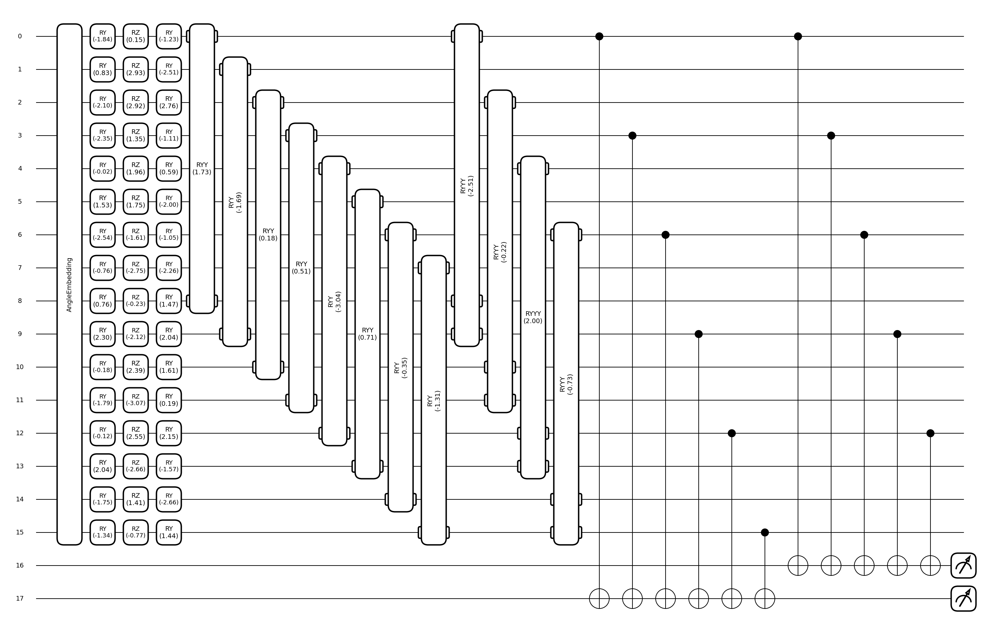

In [2]:
n_qubits = 16
fm_config = {
    "features": n_qubits,
    "rotations": "Y",
    "input_scaling": False
}

ansatz_config = {
    "n_layers": 1,
    "rotations" : ["Y {}".format(i) for i in range(n_qubits)]+ ["Z {}".format(i) for i in range(n_qubits)]+ ["Y {}".format(i) for i in range(n_qubits)]+ ["YY {} {}".format(i, i + n_qubits//2) for i in range(n_qubits//2)]+ ["YYY {} {} {}".format(i, i + n_qubits//2, (i + n_qubits//2 + 1) % n_qubits)
     for i in range(0, n_qubits//2 - 1, 2)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "random_-pi_pi",
    #"policy": "hidden-like",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    "measurement_qubits": [0,3,6,9,12,15],
    "shots": int(n_qubits**(3))
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(model=policy1,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(n_qubits))


In [ ]:
state = torch.zeros(n_qubits)

#policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)

optimizer = torch.optim.Adam(policy1.parameters(), lr=0.1)

#train policy to maximize probability of action 3 for 100 steps:
#reward = 3 if action == 3 else -1
#save probabilities of action 3
#probs_action_3 = []
#print( qml.specs(policy1.circuit)(inputs=state , params = policy1.get_weights()["params"]))
print(policy1.diff_method)
rewards = []
for i in range(100):
    action_probs = policy1.forward(state)
    loss = - torch.log(action_probs[3])
    print("time step ", i, " | action probs ", action_probs)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()




best
time step  0  | action probs  tensor([0.2434, 0.4465, 0.1084, 0.2017], grad_fn=<CopySlices>)
time step  1  | action probs  tensor([0.1785, 0.4099, 0.1104, 0.3013], grad_fn=<CopySlices>)
time step  2  | action probs  tensor([0.1575, 0.3274, 0.1016, 0.4136], grad_fn=<CopySlices>)
time step  3  | action probs  tensor([0.1272, 0.2693, 0.0730, 0.5305], grad_fn=<CopySlices>)
time step  4  | action probs  tensor([0.0945, 0.2104, 0.0532, 0.6418], grad_fn=<CopySlices>)
time step  5  | action probs  tensor([0.0657, 0.1841, 0.0447, 0.7056], grad_fn=<CopySlices>)
time step  6  | action probs  tensor([0.0376, 0.1741, 0.0332, 0.7551], grad_fn=<CopySlices>)
time step  7  | action probs  tensor([0.0308, 0.1670, 0.0278, 0.7744], grad_fn=<CopySlices>)
time step  8  | action probs  tensor([0.0181, 0.1641, 0.0244, 0.7935], grad_fn=<CopySlices>)
time step  9  | action probs  tensor([0.0112, 0.1589, 0.0225, 0.8074], grad_fn=<CopySlices>)
time step  10  | action probs  tensor([0.0061, 0.1406, 0.0183, 0.

KeyboardInterrupt: 

#### Parity like with n qubits and correlators


In [3]:
state = torch.tensor([ 1.8641, -0.9165,  0.0906,  1.9874])
state

tensor([ 1.8641, -0.9165,  0.0906,  1.9874])

Using specified device: lightning.kokkos


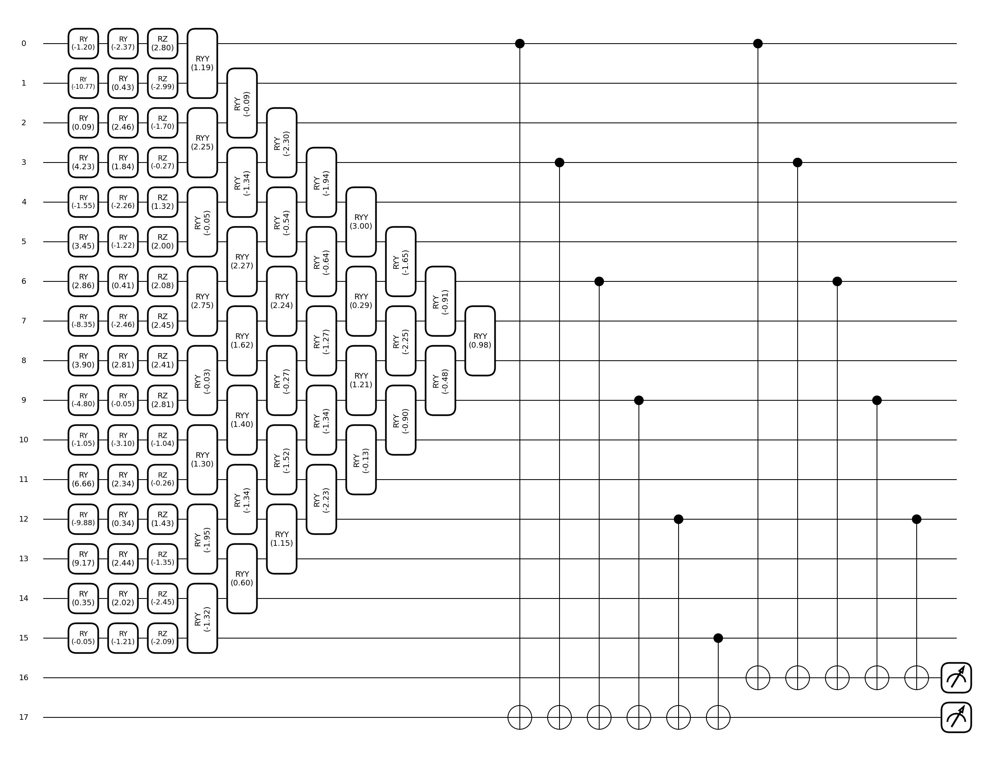

In [9]:
n_qubits = 16

def ryy_sliding_pyramid(n_qubits: int):
    """
    Returns ops_by_layer where layer t (0-indexed) uses disjoint YY pairs
    starting at s=t and ending at e_incl = (n-1) - max(0, t-1).
    
    Layer 0: s=0, e=n-1
    Layer 1: s=1, e=n-1
    Layer 2: s=2, e=n-2
    Layer 3: s=3, e=n-3
    ...
    Stops when fewer than 2 qubits remain in the [s, e] interval.
    """
    ops_by_layer = []
    for t in range(n_qubits):
        s = t
        e_incl = (n_qubits - 1) - max(0, t - 1)
        if e_incl - s + 1 < 2:
            break

        layer = []
        # Disjoint nearest-neighbor pairs within [s, e_incl]
        for i in range(s, e_incl, 2):
            if i + 1 <= e_incl:
                layer.append(f"YY {i} {i+1}")
        ops_by_layer.append(layer)

    ops_flat = [g for layer in ops_by_layer for g in layer]
    return ops_by_layer, ops_flat

def ryy_pyramid_distance(n_qubits: int):
    ops = []
    # up: distance 1,2,4,...
    d = 1
    while d < n_qubits:
        ops += [f"YY {i} {i+d}" for i in range(0, n_qubits - d, 2*d)]
        d *= 2
    # down: ... 4,2,1
    d //= 4
    while d >= 1:
        ops += [f"YY {i} {i+d}" for i in range(0, n_qubits - d, 2*d)]
        d //= 2
    return ops

_, pattern = ryy_sliding_pyramid(n_qubits)
#pattern = ryy_pyramid_distance(n_qubits)

fm_config = {
    "features": 4,
    "rotations": ["Y {}".format(i) for i in range(n_qubits)]#+["YY {} {}".format(i, i + 1) for i in range(n_qubits-1)],
}

ansatz_config = {
    "n_layers": 1,
    "rotations" : ["Y {}".format(i) for i in range(n_qubits)]+ ["Z {}".format(i) for i in range(n_qubits)]+ pattern,
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "random_-pi_pi",
    #"init": "normal_0_1",
    #"init": "zeros",
    #"policy": "hidden-like",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    #"diff_method": "adjoint",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    #"training_method": "expectation",
    "training_method": "probs",
    "torchrl": False,
    "measurement_qubits": [0,3,6,9,12,15],
    "shots": int(n_qubits**(2))
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(model=policy1,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=state)


In [10]:
#state = torch.zeros(n_qubits)

#policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)

optimizer = torch.optim.Adam(policy1.parameters(), lr=0.1)

#train policy to maximize probability of action 3 for 100 steps:
#reward = 3 if action == 3 else -1
#save probabilities of action 3
#probs_action_3 = []
#print( qml.specs(policy1.circuit)(inputs=state , params = policy1.get_weights()["params"]))
print(policy1.diff_method)
rewards = []
for i in range(100):
    action_probs = policy1.forward(state)
    loss = - torch.log(action_probs[3])
    print("time step ", i, " | action probs ", action_probs)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()




best
time step  0  | action probs  tensor([0.2031, 0.2461, 0.3594, 0.1914], grad_fn=<ToCopyBackward0>)
time step  1  | action probs  tensor([0.2617, 0.1836, 0.2617, 0.2930], grad_fn=<ToCopyBackward0>)
time step  2  | action probs  tensor([0.2656, 0.1602, 0.2031, 0.3711], grad_fn=<ToCopyBackward0>)
time step  3  | action probs  tensor([0.3438, 0.1289, 0.1133, 0.4141], grad_fn=<ToCopyBackward0>)
time step  4  | action probs  tensor([0.4414, 0.1055, 0.0664, 0.3867], grad_fn=<ToCopyBackward0>)
time step  5  | action probs  tensor([0.4258, 0.1016, 0.0391, 0.4336], grad_fn=<ToCopyBackward0>)
time step  6  | action probs  tensor([0.4219, 0.0742, 0.0742, 0.4297], grad_fn=<ToCopyBackward0>)
time step  7  | action probs  tensor([0.3945, 0.0781, 0.0898, 0.4375], grad_fn=<ToCopyBackward0>)
time step  8  | action probs  tensor([0.4180, 0.0469, 0.0781, 0.4570], grad_fn=<ToCopyBackward0>)
time step  9  | action probs  tensor([0.4805, 0.0352, 0.0312, 0.4531], grad_fn=<ToCopyBackward0>)
time step  10  

KeyboardInterrupt: 

#### Hidden qubit model with 4 local terms 

Using specified device: lightning.kokkos


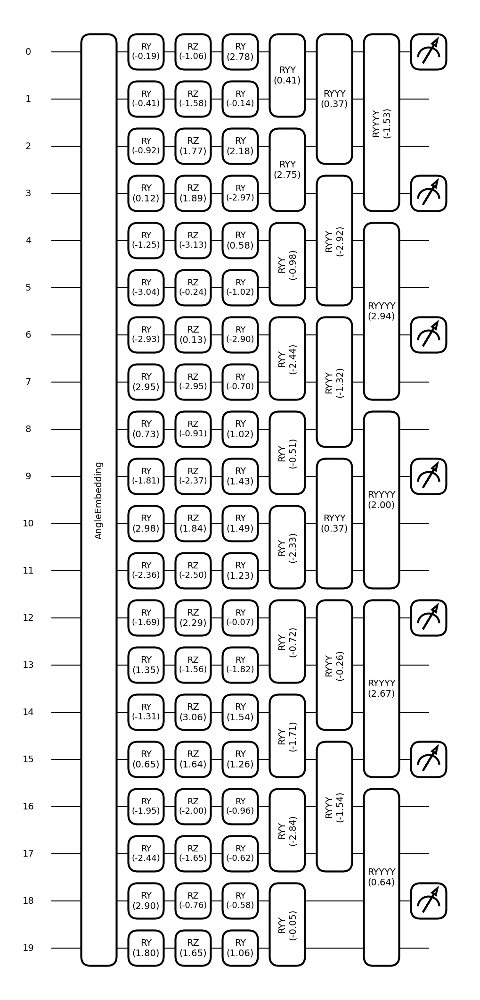

In [8]:
n_qubits = 20
fm_config = {
    "features": n_qubits,
    "rotations": "Y",
    "input_scaling": False
}

ansatz_config = {
    "n_layers": 1,
    "rotations" : ["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)]+["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 36,
    "init": "random_-pi_pi",
    "policy": "hidden-like",
    "device": "lightning.kokkos",
    "diff_method": "adjoint",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    "measurement_qubits": [0,3,6,9,12,15,18],
    #"shots": int(n_qubits**(2))
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(model=policy1,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(n_qubits))


In [5]:
state = torch.zeros(n_qubits)

#policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)

optimizer = torch.optim.Adam(policy1.parameters(), lr=0.1)

#train policy to maximize probability of action 3 for 100 steps:
#reward = 3 if action == 3 else -1
#save probabilities of action 3
#probs_action_3 = []
#print( qml.specs(policy1.circuit)(inputs=state , params = policy1.get_weights()["params"]))
print(policy1.diff_method)
rewards = []
for i in range(100):            
    action_probs = policy1.forward(state)
    loss = - torch.log(action_probs[35])
    print("time step ", i, " | action probs ", action_probs)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()
    #print upddated parameters
    for n,p in policy1.named_parameters():
        print(n, p.data)




adjoint
time step  0  | action probs  tensor([5.8955e-03, 2.3022e-02, 5.2392e-03, 1.0810e-01, 6.5066e-03, 2.5408e-02,
        5.7823e-03, 1.1930e-01, 1.9167e-03, 7.4849e-03, 1.7034e-03, 3.5144e-02,
        3.6917e-03, 1.4416e-02, 3.2807e-03, 6.7688e-02, 1.2171e-03, 4.7529e-03,
        1.0816e-03, 2.2316e-02, 1.4663e-03, 5.7258e-03, 1.3031e-03, 2.6885e-02,
        4.4831e-04, 1.7507e-03, 3.9841e-04, 8.2201e-03, 4.7882e-07, 1.8532e-06,
        4.2084e-07, 8.6940e-06, 2.0301e-02, 7.9276e-02, 1.8041e-02, 3.7223e-01],
       grad_fn=<CopySlices>)
qlayer.params tensor([-0.9883,  2.2068,  2.4788, -2.7190,  0.5829, -2.4591,  2.3419, -1.8710,
        -0.7562, -0.0808, -0.9255,  2.1641,  1.5139,  1.5228,  2.1841,  1.8461,
         0.5745, -1.6526,  1.6827, -0.1994, -0.9301, -2.3417,  2.9461,  1.5947,
         1.3672,  1.7378,  0.2715, -0.9581, -0.3208,  2.0365,  1.6422,  0.0396,
         2.2757,  0.5692, -1.4689, -3.2997, -3.0907,  2.7817,  2.6135, -2.8463,
        -2.4937, -1.6924, -2.1481,  0.

KeyboardInterrupt: 

In [12]:
fm_config = {
    "features": lambda n: n,
    "rotations": "Y",
    "input_scaling": False
}

ansatz_config = {
    "n_layers": 1,
    "rotations" : lambda n : ["Y {}".format(i) for i in range(n)]+["Z {}".format(i) for i in range(n)]+["Y {}".format(i) for i in range(n)]+["YY {} {}".format(i, i+1) for i in range(0,n-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n-3,4)],
    #"rotations" : lambda n: ["Y {}".format(i) for i in range(n)]+ ["Z {}".format(i) for i in range(n)]+ ["Y {}".format(i) for i in range(n)]+ ["YY {} {}".format(i, i + n//2) for i in range(n//2)]+ ["YYY {} {} {}".format(i, i + n//2, (i + n//2 + 1) % n) for i in range(0, n//2 - 1, 2)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 5,
    "init": "random_-pi_pi",
    "policy": "hidden-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    "measurement_qubits": lambda n: [i for i in range(0,n,3)]
    #"shots": int(n_qubits**(3))
}


variance_qubit = policy_variance(policy_class="PQCBorn", 
                            policy_config_kwargs=policy_model_config,
                            n_samples=2500,
                            action=None,
                            qubit_list=[4,6,8,9,10,12,14,16],
                            parallel=True
)

- Starting sampling for n_qubits: 4
- Starting sampling for n_qubits: 6
- Starting sampling for n_qubits: 8
- Starting sampling for n_qubits: 9
- Starting sampling for n_qubits: 10
- Starting sampling for n_qubits: 12
- Starting sampling for n_qubits: 14
- Starting sampling for n_qubits: 16


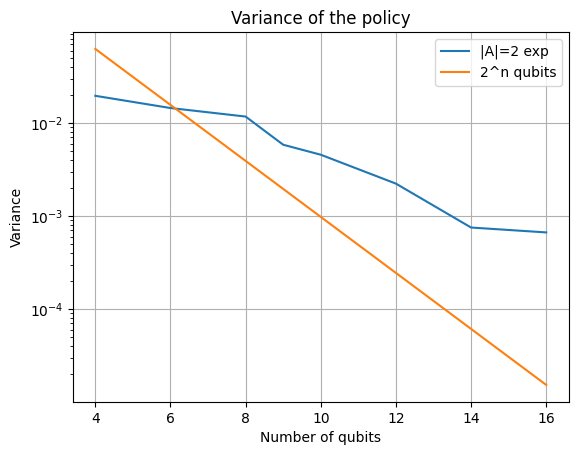

In [13]:
import matplotlib.pyplot as plt

qubit_list = [4,6,8,9,10,12,14,16]
plt.plot(qubit_list, variance_qubit, label="|A|=2 exp")
plt.plot(qubit_list, [2**(-i) for i in qubit_list], label="2^n qubits")
#plt.plot(qubit_list, [(1/16)*((0.25**i) + 0.25**(i-1) + 0.25) for i in qubit_list], label="theory LB")
#plt.plot(qubit_list, [(1/16)*((0.5**i) + 0.5**(i-1) + 0.5) for i in qubit_list], label="theory UP")
#plt.plot(qubit_list, [(1/4)*(0.5**(i/2)) for i in qubit_list], label="theory exp")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")

plt.yscale("log")

plt.title("Variance of the policy")
plt.grid()

plt.legend()

plt.show()


#### training contextual bandit

Using specified device: lightning.kokkos


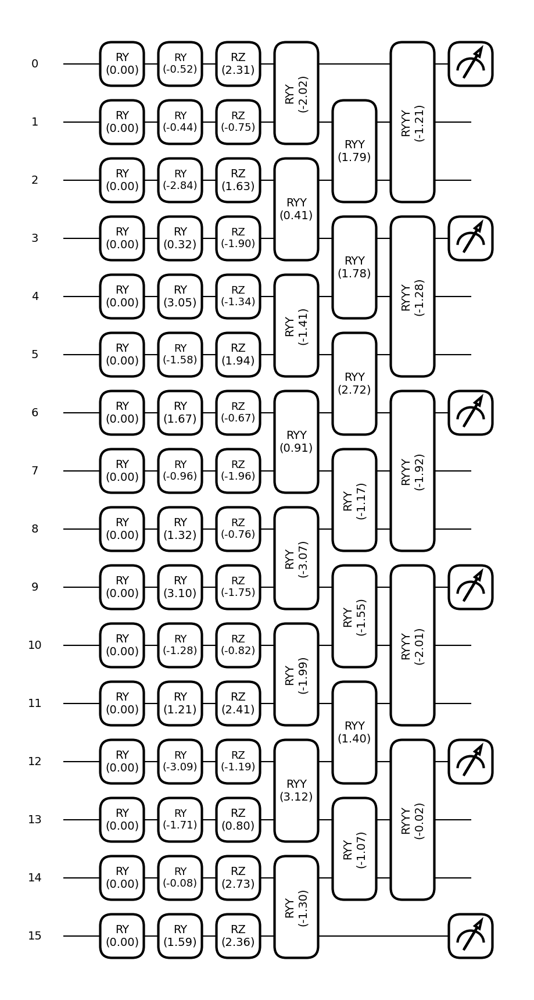

In [64]:
n_qubits = 16
fm_config = {
    "features": 4,
    "rotations": "Y",
    #"input_scaling": False
}

ansatz_config = {
    "n_layers": 1,
    "rotations" : ["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YY {} {}".format(i, i+1) for i in range(1,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] ,#+ ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 36,
    "init": "random_-pi_pi",
    "policy": "hidden-like",
    "device": "lightning.kokkos",
    "diff_method": "adjoint",
    "softmax_activation": None,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    "measurement_qubits": [0,3,6,9,12,15],
    #"shots": int(n_qubits**(3))
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(model=policy1,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(4))


In [5]:
state1 = torch.randn(4)
print(state1)
state2 = torch.randn(4)
print(state2)

tensor([0.7247, 0.4695, 0.2069, 0.1937])
tensor([ 1.1328,  0.9206,  1.0523, -1.2728])


In [66]:
#state = torch.zeros(4)

#policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)

optimizer = torch.optim.Adam(policy1.parameters(), lr=0.1)

#train policy to maximize probability of action 3 for 100 steps:
#reward = 3 if action == 3 else -1
#save probabilities of action 3
#probs_action_3 = []
#print( qml.specs(policy1.circuit)(inputs=state , params = policy1.get_weights()["params"]))
print(policy1.diff_method)
batch_size = 10
episodes = 500
rewards = []
mean_r_state1 = [] 
mean_r_state2 = []
loss = 0
for i in range(episodes): 
    context_i = np.random.choice([0,1])     
    context = state1 if context_i == 0 else state2   
    action_probs = policy1.forward(context)
    #create distribution an sample action
    dist = torch.distributions.Categorical(action_probs)
    action = dist.sample()
    reward = action if context_i == 0 else 1/(action+0.01) 
    #loss = - torch.log(action_probs[35])
    mean_r_state1.append(reward.item()) if context_i == 0 else mean_r_state2.append(reward.item())

    reward_baseline = reward - (np.mean(mean_r_state1) if context_i == 0 else np.mean(mean_r_state2))

    loss -= reward_baseline*torch.log(action_probs[action])
    #print("time step ", i, " | action probs ", action_probs)
    rewards.append(reward.item())
    print("time step ", i, "mean reward ", np.mean(rewards[-20:]))
    if (i+1)%batch_size == 0:
        loss = loss / batch_size
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        loss = 0
    #print upddated parameters




adjoint
time step  0 mean reward  20.0
time step  1 mean reward  60.0
time step  2 mean reward  45.333333333333336
time step  3 mean reward  59.0
time step  4 mean reward  52.2
time step  5 mean reward  60.166666666666664
time step  6 mean reward  55.142857142857146
time step  7 mean reward  50.875
time step  8 mean reward  56.333333333333336
time step  9 mean reward  60.7
time step  10 mean reward  64.27272727272727
time step  11 mean reward  67.25
time step  12 mean reward  69.76923076923077
time step  13 mean reward  71.92857142857143
time step  14 mean reward  68.8
time step  15 mean reward  64.50195251498371
time step  16 mean reward  62.17830824939644
time step  17 mean reward  58.72617912478745
time step  18 mean reward  56.898485486640745
time step  19 mean reward  59.05356121230871
time step  20 mean reward  58.0701725082472
time step  21 mean reward  53.082641335763036
time step  22 mean reward  57.28264133576304
time step  23 mean reward  53.68264133576304
time step  24 mean

KeyboardInterrupt: 

In [13]:
1/0.01

100.0

In [17]:
action_probs = policy1.forward(state1)
print("Final action probs for context 1 ", action_probs)
action_probs = policy1.forward(state2)
print("Final action probs for context 2 ", action_probs)

Final action probs for context 1  tensor([6.3686e-04, 5.5329e-04, 3.1031e-03, 9.1393e-03, 8.2722e-03, 7.1866e-03,
        4.0307e-02, 1.1871e-01, 3.3663e-04, 2.9246e-04, 1.6403e-03, 4.8309e-03,
        7.1843e-03, 6.2415e-03, 3.5006e-02, 1.0310e-01, 3.3575e-03, 2.9169e-03,
        1.6359e-02, 4.8182e-02, 1.8215e-03, 1.5825e-03, 8.8756e-03, 2.6140e-02,
        9.4590e-04, 8.2178e-04, 4.6090e-03, 1.3574e-02, 1.7632e-05, 1.5314e-05,
        8.5912e-05, 2.5303e-04, 2.4839e-02, 2.1580e-02, 1.2103e-01, 3.5645e-01],
       grad_fn=<CopySlices>)
Final action probs for context 2  tensor([3.9402e-01, 6.8938e-02, 1.2964e-02, 8.9200e-03, 1.4224e-02, 2.4887e-03,
        4.6799e-04, 3.2202e-04, 2.1617e-01, 3.7821e-02, 7.1122e-03, 4.8937e-03,
        4.6238e-02, 8.0899e-03, 1.5213e-03, 1.0468e-03, 7.3555e-02, 1.2869e-02,
        2.4200e-03, 1.6652e-03, 2.0705e-02, 3.6226e-03, 6.8122e-04, 4.6873e-04,
        3.7504e-02, 6.5617e-03, 1.2339e-03, 8.4902e-04, 6.6080e-04, 1.1561e-04,
        2.1743e-05, 1.

#### IQP model

Using specified device: lightning.kokkos


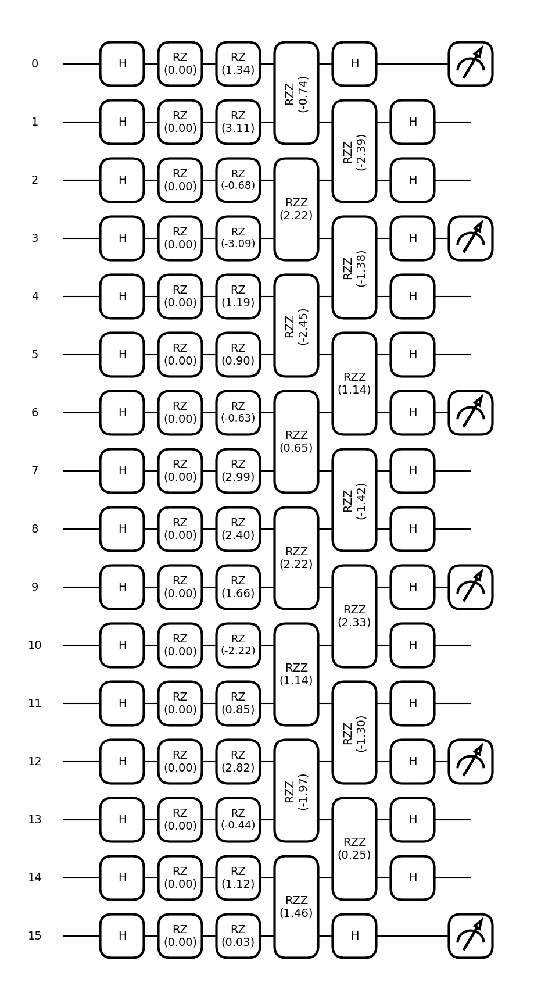

In [57]:
n_qubits = 16
fm_config = {
    "features": 4,
    "rotations": "Z",
    #"input_scaling": False
}

ansatz_config = {
    "n_layers": 1,
    "imprimitive_pattern" : [(i, i+1) for i in range(0,n_qubits-1,2)]+[(i, i+1) for i in range(1,n_qubits-1,2)],#+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": False,
}

policy_model_config = {
    "ansatz": "IQPAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 36,
    "init": "random_-pi_pi",
    "policy": "hidden-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": None,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    "measurement_qubits": [0,3,6,9,12,15],
    #"shots": int(n_qubits**(3))
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(model=policy1,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(4))


In [59]:
#state = torch.zeros(4)

#policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)

optimizer = torch.optim.Adam(policy1.parameters(), lr=0.1)

#train policy to maximize probability of action 3 for 100 steps:
#reward = 3 if action == 3 else -1
#save probabilities of action 3
#probs_action_3 = []
#print( qml.specs(policy1.circuit)(inputs=state , params = policy1.get_weights()["params"]))
print(policy1.diff_method)
batch_size = 10
episodes = 500
rewards = []
mean_r_state1 = [] 
mean_r_state2 = []
loss = 0
for i in range(episodes): 
    context_i = np.random.choice([0,1])     
    context = state1 if context_i == 0 else state2   
    action_probs = policy1.forward(context)
    #create distribution an sample action
    dist = torch.distributions.Categorical(action_probs)
    action = dist.sample()
    reward = action if context_i == 0 else 1/(action+0.01) 
    #loss = - torch.log(action_probs[35])
    mean_r_state1.append(reward.item()) if context_i == 0 else mean_r_state2.append(reward.item())

    reward_baseline = reward - (np.mean(mean_r_state1) if context_i == 0 else np.mean(mean_r_state2))

    loss -= reward_baseline*torch.log(action_probs[action])
    #print("time step ", i, " | action probs ", action_probs)
    rewards.append(reward.item())
    print("time step ", i, "mean reward ", np.mean(rewards[-20:]))
    if (i+1)%batch_size == 0:
        loss = loss / batch_size
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()
        loss = 0
    #print upddated parameters




best
time step  0 mean reward  25.0
time step  1 mean reward  12.52939447388053
time step  2 mean reward  8.36273068872591
time step  3 mean reward  6.285198989789933
time step  4 mean reward  5.036489054188133
time step  5 mean reward  8.197074211823443
time step  6 mean reward  11.026063610134381
time step  7 mean reward  9.655154277337715
time step  8 mean reward  9.693470468744636
time step  9 mean reward  8.73078564684838
time step  10 mean reward  7.942422310567715
time step  11 mean reward  9.363887118020406
time step  12 mean reward  8.669143948847285
time step  13 mean reward  9.978490809643906
time step  14 mean reward  9.317699572319786
time step  15 mean reward  8.738813643227331
time step  16 mean reward  8.244308482965126
time step  17 mean reward  7.7909171199426055
time step  18 mean reward  8.907184639945626
time step  19 mean reward  8.464455602597445
time step  20 mean reward  7.217786715086549
time step  21 mean reward  7.217477462347597
time step  22 mean reward  7

In [60]:
action_probs = policy1.forward(state1)
print("Final action probs for context 1 ", action_probs)
action_probs = policy1.forward(state2)
print("Final action probs for context 2 ", action_probs)

Final action probs for context 1  tensor([5.3414e-10, 2.1985e-09, 8.3551e-08, 3.4389e-07, 1.5141e-08, 6.2318e-08,
        2.3683e-06, 9.7477e-06, 1.0663e-06, 4.3888e-06, 1.6679e-04, 6.8649e-04,
        2.8942e-05, 1.1912e-04, 4.5271e-03, 1.8633e-02, 2.1557e-08, 8.8725e-08,
        3.3719e-06, 1.3878e-05, 6.1103e-07, 2.5150e-06, 9.5577e-05, 3.9339e-04,
        4.3032e-05, 1.7712e-04, 6.7311e-03, 2.7705e-02, 1.1680e-03, 4.8075e-03,
        1.8270e-01, 7.5198e-01, 3.2182e-13, 1.3246e-12, 5.0339e-11, 2.0719e-10],
       grad_fn=<CopySlices>)
Final action probs for context 2  tensor([9.5126e-01, 2.6182e-03, 3.7373e-02, 1.0286e-04, 1.9974e-03, 5.4976e-06,
        7.8476e-05, 2.1599e-07, 1.5457e-03, 4.2543e-06, 6.0728e-05, 1.6714e-07,
        8.3334e-06, 2.2937e-08, 3.2741e-07, 9.0114e-10, 3.2439e-03, 8.9283e-06,
        1.2745e-04, 3.5078e-07, 6.8114e-06, 1.8747e-08, 2.6761e-07, 7.3656e-10,
        5.2710e-06, 1.4508e-08, 2.0709e-07, 5.6998e-10, 1.1054e-08, 3.0426e-11,
        4.3431e-10, 1.

In [1]:
import torch
import numpy as np
from qasp import * 

HERE!
EXPVAL QLAYER -  tensor([ 8.8679e-11,  5.7117e-11, -6.5096e-02], grad_fn=<CatBackward0>)
MOMENTS tensor([ 8.8679e-11,  5.7117e-11, -6.5096e-02], grad_fn=<CatBackward0>)
PROBS after moments tensor([0.2337, 0.2663, 0.2663, 0.2337], grad_fn=<CopySlices>)
policy after moments tensor([0.2337, 0.2663, 0.2663, 0.2337], grad_fn=<CopySlices>)
[0.2337259 0.2662741 0.2662741 0.2337259]


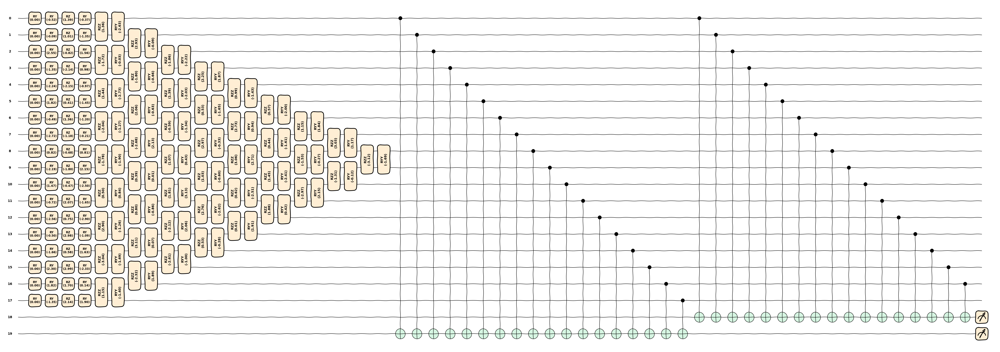

In [6]:
n_qubits=18

fm_config = {
    "features": n_qubits,
    "rotations": "Y",
    "input_scaling": False
}

def SU4(a,b,l):
    if l==0:
        return ["Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b), "XX {} {}".format(a,b), "YY {} {}".format(a,b) , "ZZ {} {}".format(a,b), "Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b)]
    else:

        return ["ZZ {} {}".format(a,b), "Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b)]


def nn(a,b,l):
    if l==True:
        return ["Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b), "ZZ {} {}".format(a,b), "YY {} {}".format(a,b)]
    else:

        return ["ZZ {} {}".format(a,b), "YY {} {}".format(a,b)]
        
rotation_list = ["Y {}".format(i) for i in range(n_qubits)]
qubit_list = list(range(n_qubits))
orig = n_qubits
while len(qubit_list) >= 2:

    for i in range(0,len(qubit_list)-1,2):
        rotation_list += nn(qubit_list[i], qubit_list[i+1],len(qubit_list)==orig)

    qubit_list.pop(0)
    qubit_list.pop(-1)

#rotation_list += rotation_list[::-1]

ansatz_config = {
    "n_layers": 1,
    "rotations" : rotation_list,
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "random_-pi_pi",
    #"init": "constant",
    #"init": "normal_0_1",
    "policy": "parity-like",
    #"policy": "contiguous-like",
    "device": "lightning.kokkos",
    #"device": "lightning.pp",
    #"device": "default.tensor",
    #"diff_method": "adjoint",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    #"training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [i for i in range(0,n_qubits,3)],
    #"shots": int(n_qubits**(2)),
    "pp_truncation": 4, # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
    "parity_cnot_decomposition": True
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)

fig, ax = draw_model(model=policy1,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(n_qubits))


state = torch.zeros(n_qubits)

pi1 = policy1.forward(state).detach().numpy()
print(pi1)


In [8]:
state = torch.zeros(n_qubits)

#for t in range(10)
#pi1 = policy1.forward(state).detach().numpy()
#if rank == 0:
#    print("POLICY ",pi1)

optimizer = torch.optim.Adam(policy1.parameters(), lr=0.1)

for t in range(10):   
    action_probs = policy1.forward(state)
    print("time step ", t, "action probabilities ", action_probs, flush=True)
    loss = -torch.log(action_probs[0])
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()

HERE!
EXPVAL QLAYER -  tensor([-9.7429e-15,  4.0019e-14,  7.9369e-01], grad_fn=<CatBackward0>)
MOMENTS tensor([-9.7429e-15,  4.0019e-14,  7.9369e-01], grad_fn=<CatBackward0>)
PROBS after moments tensor([0.4484, 0.0516, 0.0516, 0.4484], grad_fn=<CopySlices>)
policy after moments tensor([0.4484, 0.0516, 0.0516, 0.4484], grad_fn=<CopySlices>)
time step  0 action probabilities  tensor([0.4484, 0.0516, 0.0516, 0.4484], grad_fn=<CopySlices>)
HERE!
EXPVAL QLAYER -  tensor([ 5.2915e-16, -8.3142e-15,  9.0141e-01], grad_fn=<CatBackward0>)
MOMENTS tensor([ 5.2915e-16, -8.3142e-15,  9.0141e-01], grad_fn=<CatBackward0>)
PROBS after moments tensor([0.4754, 0.0246, 0.0246, 0.4754], grad_fn=<CopySlices>)
policy after moments tensor([0.4754, 0.0246, 0.0246, 0.4754], grad_fn=<CopySlices>)
time step  1 action probabilities  tensor([0.4754, 0.0246, 0.0246, 0.4754], grad_fn=<CopySlices>)
HERE!
EXPVAL QLAYER -  tensor([-6.3428e-15, -1.8438e-14,  9.6534e-01], grad_fn=<CatBackward0>)
MOMENTS tensor([-6.3428e-

In [1]:
import torch
import numpy as np
from qasp import * 

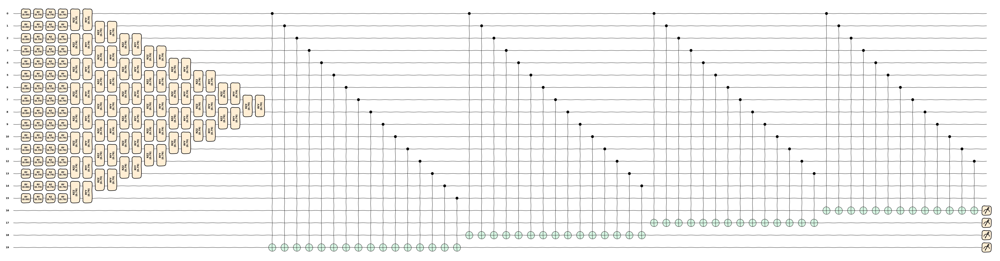

In [10]:
n_qubits=16

fm_config = {
    "features": n_qubits,
    "rotations": "Y",
    "input_scaling": False
}

def SU4(a,b,l):
    if l==0:
        return ["Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b), "XX {} {}".format(a,b), "YY {} {}".format(a,b) , "ZZ {} {}".format(a,b), "Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b)]
    else:

        return ["ZZ {} {}".format(a,b), "Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b)]


def nn(a,b,l):
    if l==True:
        return ["Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b), "ZZ {} {}".format(a,b), "YY {} {}".format(a,b)]
    else:

        return ["ZZ {} {}".format(a,b), "YY {} {}".format(a,b)]
        
rotation_list = ["Y {}".format(i) for i in range(n_qubits)]
qubit_list = list(range(n_qubits))
orig = n_qubits
while len(qubit_list) >= 2:

    for i in range(0,len(qubit_list)-1,2):
        rotation_list += nn(qubit_list[i], qubit_list[i+1],len(qubit_list)==orig)

    qubit_list.pop(0)
    qubit_list.pop(-1)

#rotation_list += rotation_list[::-1]

ansatz_config = {
    "n_layers": 1,
    "rotations" : rotation_list,
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 16,
    #"init": "random_-pi_pi",
    "init": "constant",
    #"init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    #"device": "lightning.pp",
    #"device": "default.tensor",
    #"diff_method": "adjoint",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    #"training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [i for i in range(0,n_qubits,3)],
    #"shots": int(n_qubits**(2)),
    "pp_truncation": 4, # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
    "parity_cnot_decomposition": True
}


policy2 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
#policy2.qlayer.load_state_dict(policy1.qlayer.state_dict())
#print(policy2.qlayer.state_dict()["params"])

fig, ax = draw_model(model=policy2,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(n_qubits))

#state = torch.zeros(n_qubits)

#pi2 = policy2.forward(state).detach().numpy()
#print(pi2)


In [6]:
#import categorical distribution from torch
from torch.distributions import Categorical

In [ ]:
state = torch.zeros(n_qubits)

#for t in range(10)
#pi1 = policy1.forward(state).detach().numpy()
#if rank == 0:
#    print("POLICY ",pi1)

optimizer = torch.optim.Adam(policy2.parameters(), lr=0.1)

for t in range(100):   
    
    action_probs = policy2.forward(state)
    #create categorical distribution and sample action
    #dist = Categorical(action_probs)
    #action = dist.sample()
    #reward = 1/(action.item() + 0.01)
    print("time step ", t, "action probabilities ", action_probs, flush=True)
    loss = -torch.log(action_probs[0])
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()

HERE!
policy after moments tensor([0.0104, 0.0512, 0.1010, 0.0379, 0.0705, 0.1423, 0.0639, 0.0228, 0.0228,
        0.0639, 0.1423, 0.0705, 0.0379, 0.1010, 0.0512, 0.0104],
       grad_fn=<CopySlices>)
time step  0 action probabilities  tensor([0.0104, 0.0512, 0.1010, 0.0379, 0.0705, 0.1423, 0.0639, 0.0228, 0.0228,
        0.0639, 0.1423, 0.0705, 0.0379, 0.1010, 0.0512, 0.0104],
       grad_fn=<CopySlices>)
HERE!
policy after moments tensor([0.0403, 0.0802, 0.0808, 0.0372, 0.0577, 0.0967, 0.0663, 0.0407, 0.0407,
        0.0663, 0.0967, 0.0577, 0.0372, 0.0808, 0.0802, 0.0403],
       grad_fn=<CopySlices>)
time step  1 action probabilities  tensor([0.0403, 0.0802, 0.0808, 0.0372, 0.0577, 0.0967, 0.0663, 0.0407, 0.0407,
        0.0663, 0.0967, 0.0577, 0.0372, 0.0808, 0.0802, 0.0403],
       grad_fn=<CopySlices>)
HERE!
policy after moments tensor([0.0920, 0.1042, 0.0583, 0.0328, 0.0416, 0.0595, 0.0568, 0.0549, 0.0549,
        0.0568, 0.0595, 0.0416, 0.0328, 0.0583, 0.1042, 0.0920],
       g

In [2]:
import numpy as np

In [13]:
import torch
import numpy as np
from qasp import * 

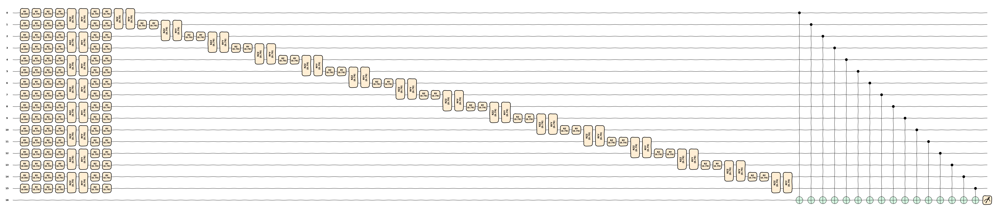

In [23]:
n_qubits=16

fm_config = {
    "features": 4,
    "rotations": "Y",
    "input_scaling": False
}

def SU4(a,b,l):
    if l==0:
        return ["Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b), "XX {} {}".format(a,b), "YY {} {}".format(a,b) , "ZZ {} {}".format(a,b), "Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b)]
    else:

        return ["ZZ {} {}".format(a,b), "Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b)]


def nn(a,b,l):
    if l==True:
        return ["Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b), "ZZ {} {}".format(a,b), "YY {} {}".format(a,b)]
    else:

        return ["ZZ {} {}".format(a,b), "YY {} {}".format(a,b)]
        
rotation_list = ["Y {}".format(i) for i in range(n_qubits)]
qubit_list = list(range(n_qubits))
orig = n_qubits
#while len(qubit_list) >= 2:

for i in range(0,len(qubit_list)-1,2):
    rotation_list += nn(qubit_list[i], qubit_list[i+1],len(qubit_list)==orig)
for i in range(0,len(qubit_list)-1):
    rotation_list += nn(qubit_list[i], qubit_list[i+1],len(qubit_list)==orig)

    #qubit_list.pop(0)
    #qubit_list.pop(-1)

#rotation_list += rotation_list[::-1]

ansatz_config = {
    "n_layers": 1,
    "rotations" : rotation_list,
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    #"init": "random_-pi_pi",
    "init": "constant",
    #"init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.qubit",
    #"device": "default.tensor",
    #"device": "lightning.pp",
    #"device": "default.tensor",
    #"diff_method": "adjoint",
    "diff_method": "adjoint",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    #"training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [i for i in range(0,n_qubits,3)],
    #"shots": int(n_qubits**(2)),
    "pp_truncation": 4, # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
    "parity_cnot_decomposition": True
}


policy_model = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
#policy2.qlayer.load_state_dict(policy1.qlayer.state_dict())
#print(policy2.qlayer.state_dict()["params"])

fig, ax = draw_model(model=policy_model,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=4, inputs=torch.zeros(4))

#state = torch.zeros(n_qubits)

#pi2 = policy2.forward(state).detach().numpy()
#print(pi2)m


In [9]:
state = torch.zeros(n_qubits)

pi2 = policy2.forward(state).detach().numpy()
pi2

array([0.21805863, 0.28051522, 0.30264366, 0.1987825 ], dtype=float32)

In [12]:
state = torch.zeros(n_qubits)

optimizer = torch.optim.Adam(policy2.parameters(), lr=0.1)

#train policy to maximize probability of action 3 for 100 steps:
#reward = 3 if action == 3 else -1
#save probabilities of action 3
#probs_action_3 = []
#print( qml.specs(policy1.circuit)(inputs=state , params = policy1.get_weights()["params"]))
print(policy2.diff_method)
rewards = []
for i in range(100):
    action_probs = policy2.forward(state)
    loss = - torch.log(action_probs[0])
    print(action_probs)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()




adjoint
tensor([0.2181, 0.2805, 0.3026, 0.1988], grad_fn=<CopySlices>)
tensor([0.4081, 0.1502, 0.2565, 0.1851], grad_fn=<CopySlices>)
tensor([0.6447, 0.0623, 0.1715, 0.1215], grad_fn=<CopySlices>)
tensor([0.7777, 0.0347, 0.0767, 0.1109], grad_fn=<CopySlices>)
tensor([0.8247, 0.0329, 0.0210, 0.1214], grad_fn=<CopySlices>)
tensor([0.8232, 0.0417, 0.0064, 0.1287], grad_fn=<CopySlices>)
tensor([0.8176, 0.0490, 0.0139, 0.1196], grad_fn=<CopySlices>)
tensor([0.8269, 0.0483, 0.0280, 0.0969], grad_fn=<CopySlices>)
tensor([0.8510, 0.0404, 0.0396, 0.0690], grad_fn=<CopySlices>)
tensor([0.8769, 0.0292, 0.0438, 0.0501], grad_fn=<CopySlices>)
tensor([0.8962, 0.0185, 0.0406, 0.0446], grad_fn=<CopySlices>)
tensor([0.9108, 0.0106, 0.0321, 0.0465], grad_fn=<CopySlices>)
tensor([0.9208, 0.0066, 0.0214, 0.0513], grad_fn=<CopySlices>)
tensor([0.9271, 0.0062, 0.0118, 0.0549], grad_fn=<CopySlices>)
tensor([0.9328, 0.0088, 0.0053, 0.0530], grad_fn=<CopySlices>)
tensor([0.9430, 0.0131, 0.0020, 0.0419], grad_f

KeyboardInterrupt: 

In [24]:
algo = REINFORCE(
    policy        = policy_model,         # your PQCBorn
    env_name      = "CartPole-v0",
    gamma         = 0.99,
    lr            = 1e-1,
    batch_episodes= 5,
    logits        = False              # set True if action_logits returns logits
)


/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


In [25]:

returns = algo.train(num_episodes=500)

qlayer.input_scaling_params tensor([0.6854, 0.6854, 0.8854, 0.8854, 0.8854, 0.8854, 0.6854, 0.6854, 0.6854,
        0.6854, 0.8854, 0.8854, 0.6854, 0.6854, 0.8854, 0.8854, 0.6856, 0.6861,
        0.8842, 0.6859, 0.8854, 0.8854, 0.6854, 0.6854, 0.8854, 0.8854, 0.6854,
        0.6854, 0.8854, 0.8854, 0.6854, 0.6854, 0.8853, 0.8854, 0.6854, 0.6854,
        0.8854, 0.8854, 0.6854, 0.6854, 0.6855, 0.6854, 0.8852, 0.8854, 0.8853,
        0.8854, 0.6854, 0.6854, 0.6854, 0.6854, 0.8854, 0.8854, 0.6854, 0.6854,
        0.8854, 0.8854, 0.6854, 0.6854, 0.8854, 0.8854, 0.8854, 0.8854, 0.6854,
        0.6854])
qlayer.input_scaling_params tensor([0.5965, 0.5894, 0.8239, 0.9391, 0.9839, 0.9840, 0.7100, 0.5854, 0.6846,
        0.6088, 0.9855, 0.9688, 0.5991, 0.5925, 0.8270, 0.9775, 0.7594, 0.7604,
        0.9586, 0.6109, 0.8189, 0.9802, 0.6065, 0.6031, 0.9669, 0.9693, 0.7206,
        0.6016, 0.8425, 0.9835, 0.6018, 0.5979, 0.9753, 0.9703, 0.5979, 0.6035,
        0.8529, 0.9834, 0.6006, 0.5974, 0.7572,

KeyboardInterrupt: 

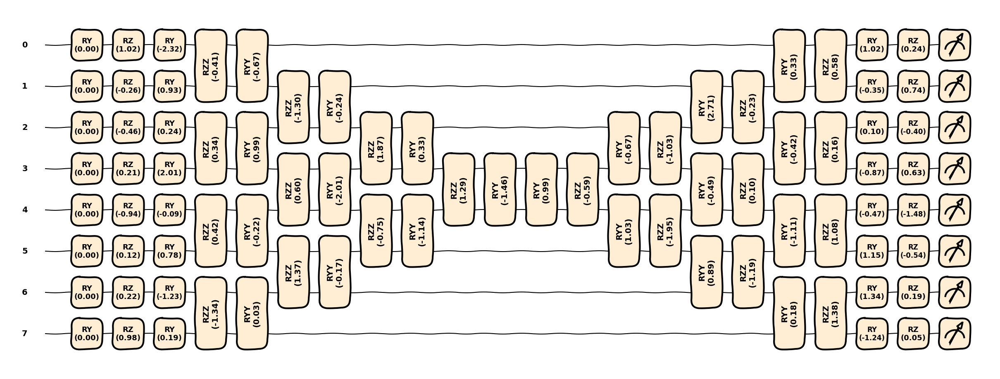

In [2]:
n_qubits=8

fm_config = {
    "features": n_qubits,
    "rotations": "Y",
    "input_scaling": False
}

def SU4(a,b,l):
    if l==0:
        return ["Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b), "XX {} {}".format(a,b), "YY {} {}".format(a,b) , "ZZ {} {}".format(a,b), "Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b)]
    else:

        return ["ZZ {} {}".format(a,b), "Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b)]


def nn(a,b,l):
    if l==True:
        return ["Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b), "ZZ {} {}".format(a,b), "YY {} {}".format(a,b)]
    else:

        return ["ZZ {} {}".format(a,b), "YY {} {}".format(a,b)]
        
rotation_list = []
qubit_list = list(range(n_qubits))
orig = n_qubits
while len(qubit_list) >= 2:

    for i in range(0,len(qubit_list)-1,2):
        rotation_list += nn(qubit_list[i], qubit_list[i+1],len(qubit_list)==orig)

    qubit_list.pop(0)
    qubit_list.pop(-1)

rotation_list += rotation_list[::-1]

ansatz_config = {
    "n_layers": 1,
    "rotations" : rotation_list,
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 64,
    #"init": "random_-pi_pi",
    #"init": "constant",
    #"init": "normal_0_1",
    "policy": "parity-like",
    #"device": "lightning.kokkos",
    "device": "lightning.pp",
    #"device": "default.tensor",
    #"diff_method": "adjoint",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    #"training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [i for i in range(0,n_qubits,3)],
    #"shots": int(n_qubits**(2)),
    "pp_truncation": 4, # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
    "parity_cnot_decomposition": False
}


policy2 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
#policy2.qlayer.load_state_dict(policy1.qlayer.state_dict())
#print(policy2.qlayer.state_dict()["params"])

fig, ax = draw_model(model=policy2,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(n_qubits))

state = torch.zeros(n_qubits)

#pi2 = policy2.forward(state).detach().numpy()
#print(pi2)

In [1]:
from qasp import * 
import torch

In [ ]:
action_set = [8]

variances_action = [] 

for n_actions in action_set:
    print("Running variance for n_actions = ", n_actions)
    fm_config = {
        "features": 4,
        "rotations": "Z",
    }

    ansatz_config = {
        "n_layers": 3,
        "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
        "reuploading": False,
        "include_imprimitive": True,
        "imprimitive": "CZ",
        "imprimitive_pattern": "all_to_all",
        "include_final_imprimitive": False,
        "include_feature_map_first": False,
        "include_hadamards_initial": True
    }

    policy_model_config = {
        "ansatz": "AngleAnsatz",
        "ansatz_config": ansatz_config,
        "feature_map": "NeuralEmbedding",
        "feature_map_config": fm_config,
        "n_actions": n_actions,
        "init": "random_-pi_pi",
        "policy": "parity-like",
        "device": "lightning.kokkos",
        "diff_method": "best",
        "softmax_activation": False,
        "output_scaling": None,
        "training_method": "expectation",
        "torchrl": False,
        "measurement_qubits": lambda n: [i for i in range(n)],
        #"shots": int(n_qubits**(2)),
        "parity_cnot_decomposition": False,
    }
    variance_qubit = policy_variance(policy_class="PQCBorn", 
                            policy_config_kwargs=policy_model_config,
                            n_samples=2000,
                            #action=0,
                            qubit_list=[4,6,8,9,10,12,14],
                            parallel=True)

    variances_action.append(variance_qubit[0])
#policy = create_model("PQCBorn", policy_model_config, n_qubits=5)

#fig, ax = draw_model(model=policy,policy_class="PQCBorn", n_qubits=5, num_inputs=5, inputs=torch.zeros(5))

Running variance for n_actions =  8


2026-06-30 16:23:08,367	INFO worker.py:1888 -- Started a local Ray instance.


- Starting sampling for n_qubits: 4


(raylet) [2026-06-30 16:23:18,293 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.5144 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 16:23:28,306 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.5141 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 16:23:38,354 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.5139 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


- Starting sampling for n_qubits: 6


(raylet) [2026-06-30 16:23:48,414 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.5137 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 16:23:58,457 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.5135 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


... (7 outputs left out)

(raylet) [2026-06-30 16:26:49,289 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.5122 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 16:26:59,324 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.5121 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 16:27:09,345 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.5108 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 16:27:19,373 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.5106 GB; capacity: 421.525 GB. Object creation

- Starting sampling for n_qubits: 14


(raylet) [2026-06-30 16:32:30,668 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.4401 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 16:32:40,685 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.4398 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 16:32:50,694 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.4396 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 16:33:00,724 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 10.4383 GB; capacity: 421.525 GB. Object creation

(raylet) [2026-06-30 17:06:28,363 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 8.39965 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 17:06:38,438 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 8.39078 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 17:06:48,468 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 8.38995 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-06-30 17:06:58,477 E 86858 34970623] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-06-30_16-23-06_733295_86422 is over 95% full, available space: 8.39229 GB; capacity: 421.525 GB. Object creation

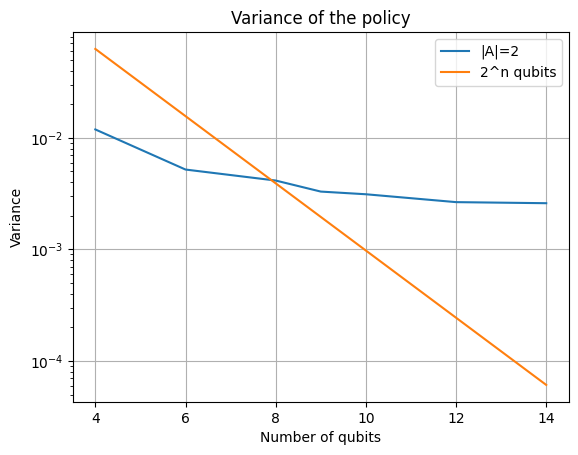

In [3]:
import matplotlib.pyplot as plt

qubit_list = [4,6,8,9,10,12,14]
plt.plot(qubit_list, variances_action[0], label="|A|=2")
plt.plot(qubit_list, [2**(-i) for i in qubit_list], label="2^n qubits")
#plt.plot(qubit_list, [(1/16)*((0.25**i) + 0.25**(i-1) + 0.25) for i in qubit_list], label="theory LB")
#plt.plot(qubit_list, [(1/16)*((0.5**i) + 0.5**(i-1) + 0.5) for i in qubit_list], label="theory UP")
#plt.plot(qubit_list, [(1/4)*(0.5**(i/2)) for i in qubit_list], label="theory exp")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")

plt.yscale("log")

plt.title("Variance of the policy")
plt.grid()

plt.legend()

plt.show()

In [4]:
#save variances_action in .json in folder tests_cartpole_training/
import json
with open("tests_cartpole_training/jsons/variances_action_2_n.json", "w") as f:
    json.dump(variances_action, f)

In [28]:
import torch




In [38]:
n_qubits = 16

fm_config = {
    "features": n_qubits,
    "rotations": "Z",
    "input_scaling": False
}

ansatz_config = {
    "n_layers": 1,
    "rotations" : ["Z {}".format(i) for i in range(n_qubits)]+["ZZ {} {}".format(i, j) for i in range(n_qubits-1) for j in range(i+1, n_qubits)] + ["X {}".format(i) for i in range(n_qubits)],
    #"rotations" : lambda n: ["Y {}".format(i) for i in range(n)]+ ["Z {}".format(i) for i in range(n)]+ ["Y {}".format(i) for i in range(n)]+ ["YY {} {}".format(i, i + n//2) for i in range(n//2)]+ ["YYY {} {} {}".format(i, i + n//2, (i + n//2 + 1) % n) for i in range(0, n//2 - 1, 2)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain",
    "include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2**n_qubits,
    "init": "normal_0_1",
    "policy": "hidden-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": lambda n: [n-1]
    #"shots": int(n_qubits**(3))
}


policy2 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
#policy2.qlayer.load_state_dict(policy1.qlayer.state_dict())
#print(policy2.qlayer.state_dict()["params"])

fig, ax = draw_model(model=policy2,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=n_qubits, inputs=torch.zeros(n_qubits))


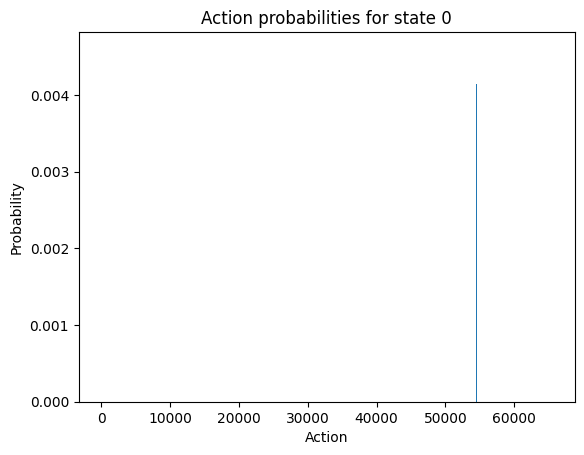

In [39]:

state = torch.zeros(n_qubits)

pi2 = policy2.forward(state).detach().numpy()

#plot histogram of pi2

plt.bar(range(len(pi2)), pi2)
plt.xlabel("Action")
plt.ylabel("Probability")
plt.title("Action probabilities for state 0")
plt.show()


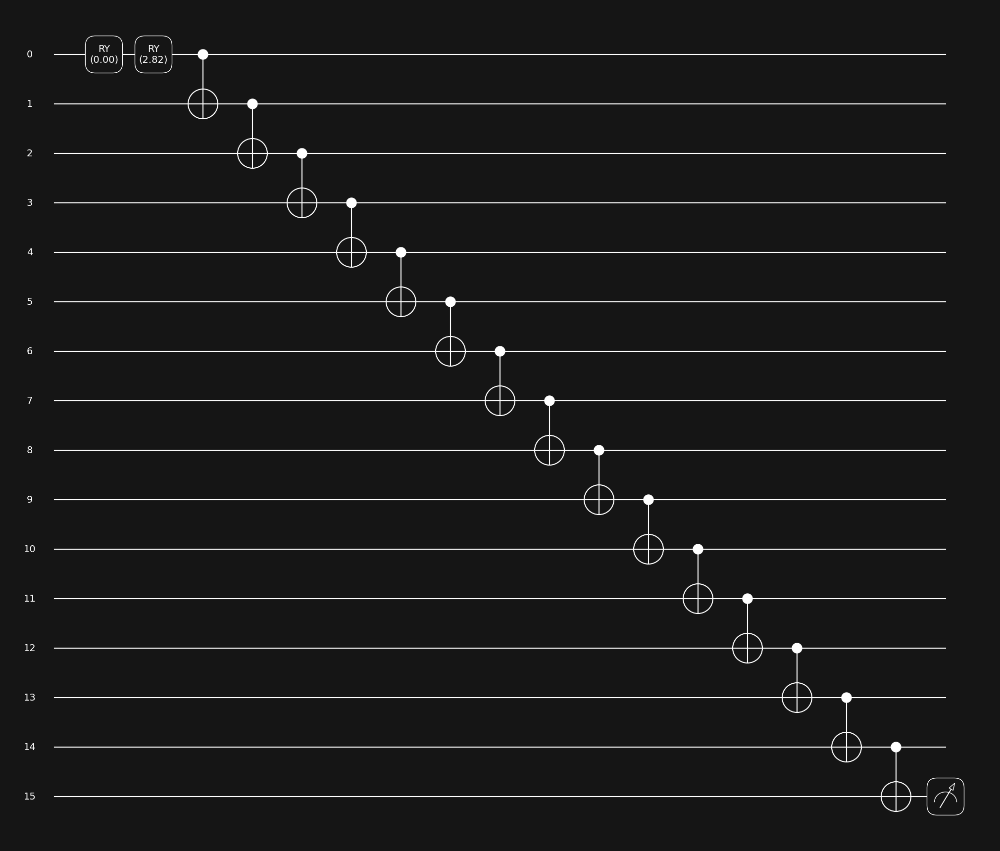

In [45]:
n_qubits = 16
fm_config = {
    "features": 1,
    "rotations": ["Y 0"],
    #"imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    #"imprimitive": "CZ",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 1,
    #"imprimitive_pattern" : ["Y 0"],
    "rotations" : ["Y 0"],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain",
    #"include_final_imprimitive": False,
    #"include_feature_map_first": False,
    #"include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    #"init": "normal_0_1",
    "init": "random_-pi_pi",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    "measurement_qubits": [15],
    "shots": n_qubits**(2),
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=1,
    inputs=torch.zeros(1),
)



In [46]:
steps = 500
state = torch.zeros(n_qubits)

optimizer = torch.optim.Adam(policy1.parameters(), lr=0.1)

probs_list=[]
losses=[]
for step in range(steps):
    probs = policy1.forward(state)
    loss = -torch.log(probs[-1]) # assuming action 0 is the optimal action for this state
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    print(f"Step {step+1}/{steps}, probs: {probs.detach().numpy()}")
    probs_list.append(probs.detach().numpy())
    losses.append(loss.item())


Step 1/500, probs: [0.015625 0.984375]
Step 2/500, probs: [0.00390625 0.99609375]
Step 3/500, probs: [0. 1.]
Step 4/500, probs: [0. 1.]
Step 5/500, probs: [0. 1.]
Step 6/500, probs: [0. 1.]
Step 7/500, probs: [0.00390625 0.99609375]
Step 8/500, probs: [0.01171875 0.98828125]
Step 9/500, probs: [0.0078125 0.9921875]
Step 10/500, probs: [0. 1.]
Step 11/500, probs: [0. 1.]
Step 12/500, probs: [0. 1.]
Step 13/500, probs: [0. 1.]
Step 14/500, probs: [0. 1.]
Step 15/500, probs: [0. 1.]
Step 16/500, probs: [0. 1.]
Step 17/500, probs: [0.00390625 0.99609375]
Step 18/500, probs: [0. 1.]
Step 19/500, probs: [0.00390625 0.99609375]
Step 20/500, probs: [0. 1.]
Step 21/500, probs: [0.00390625 0.99609375]
Step 22/500, probs: [0. 1.]
Step 23/500, probs: [0. 1.]
Step 24/500, probs: [0. 1.]
Step 25/500, probs: [0. 1.]
Step 26/500, probs: [0. 1.]
Step 27/500, probs: [0. 1.]
Step 28/500, probs: [0. 1.]
Step 29/500, probs: [0. 1.]
Step 30/500, probs: [0. 1.]
Step 31/500, probs: [0. 1.]
Step 32/500, probs:

In [7]:
action_set = [4,8,16,32]
n_qubits = 14

variances_action=[]

for action in action_set:
    print("Computing variance for action ", action)
    fm_config = {
        "features": n_qubits,
        "rotations": "Z",
        "input_scaling": False
    }

    ansatz_config = {
        "n_layers": 1,
        #"rotations" : lambda n : ["Z {}".format(i) for i in range(n)]+["ZZ {} {}".format(i, j) for i in range(n-1) for j in range(i+1, n)] + ["X {}".format(i) for i in range(n)],
        #"rotations" : lambda n: ["Y {}".format(i) for i in range(n)]+ ["Z {}".format(i) for i in range(n)]+ ["Y {}".format(i) for i in range(n)]+ ["YY {} {}".format(i, i + n//2) for i in range(n//2)]+ ["YYY {} {} {}".format(i, i + n//2, (i + n//2 + 1) % n) for i in range(0, n//2 - 1, 2)],
        "reuploading": False,
        #"include_imprimitive": True,
        #"imprimitive": "CNOT",
        "imprimitive_pattern": [(i, i + 1) for i in range(0, n_qubits - 1, 2)] + [(i, i + 1) for i in range(1, n_qubits - 1, 2)]
        #"include_hadamards_initial": False
    }

    policy_model_config = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": ansatz_config,
        "feature_map": "AngleEmbedding",
        "feature_map_config": fm_config,
        "n_actions": action,
        "init": "random_-pi_pi",
        "policy": "parity-like",
        "device": "lightning.kokkos",
        "diff_method": "best",
        "softmax_activation": False,
        "output_scaling": None,
        "training_method": "expectation",
        "torchrl": False,
        #"measurement_qubits": lambda n: [i for i in range(n)],
        #"shots": int(n_qubits**(3)),
        "parity_cnot_decomposition": False
    }
   #policy = create_model("PQCBorn", policy_model_config, n_qubits=14)

    variance_qubit = policy_variance(policy_class="PQCBorn", 
                            policy_config_kwargs=policy_model_config,
                            n_samples=2000,
                            action=-1,
                            qubit_list=[14],
                            parallel=True)
    print("Variance for action ", action, " is ", variance_qubit)
    variances_action.append(variance_qubit[0][0])

Computing variance for action  4
- Starting sampling for n_qubits: 14
Variance for action  4  is  ([np.float64(0.015502644603479662)], {14: [0.06545372307300568, 0.30143165588378906, 0.4488072693347931, 0.23599675297737122, 0.24439889192581177, 0.2810930907726288, 0.2896873652935028, 0.30617716908454895, 0.29993686079978943, 0.23509979248046875, 0.341560959815979, 0.32003259658813477, 0.2170586735010147, 0.43582969903945923, 0.2293596863746643, 0.25468266010284424, 0.2575714886188507, 0.10045874118804932, 0.36048591136932373, 0.2579563856124878, 0.4954959452152252, 0.30867600440979004, 0.3281027674674988, 0.2629128694534302, 0.20386359095573425, 0.2391871064901352, 0.28557905554771423, 0.2584860622882843, 0.1479029357433319, 0.4670569896697998, 0.33970174193382263, 0.33073559403419495, 0.4985222816467285, 0.46933290362358093, 0.4434186518192291, 0.3555152416229248, 0.26808369159698486, 0.3577757477760315, 0.2800672650337219, 0.15594182908535004, 0.20841914415359497, 0.38487982749938965

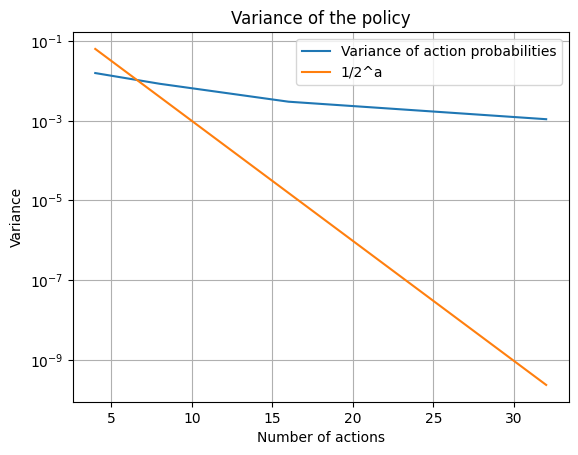

In [11]:
import matplotlib.pyplot as plt

action_set = [4,8,16,32]
plt.plot(action_set, variances_action, label="Variance of action probabilities")
plt.plot(action_set, [2**(-i) for i in action_set], label="1/2^a")
#plt.plot(qubit_list, [(1/16)*((0.25**i) + 0.25**(i-1) + 0.25) for i in qubit_list], label="theory LB")
#plt.plot(qubit_list, [(1/16)*((0.5**i) + 0.5**(i-1) + 0.5) for i in qubit_list], label="theory UP")
#plt.plot(qubit_list, [(1/4)*(0.5**(i/2)) for i in qubit_list], label="theory exp")

plt.xlabel("Number of actions")
plt.ylabel("Variance")

plt.yscale("log")

plt.title("Variance of the policy")
plt.grid()

plt.legend()

plt.show()

In [1]:
from qasp import *
import torch
import qasp 
from pennylane import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt

Observation  tensor([0., 0., 0., 0.])


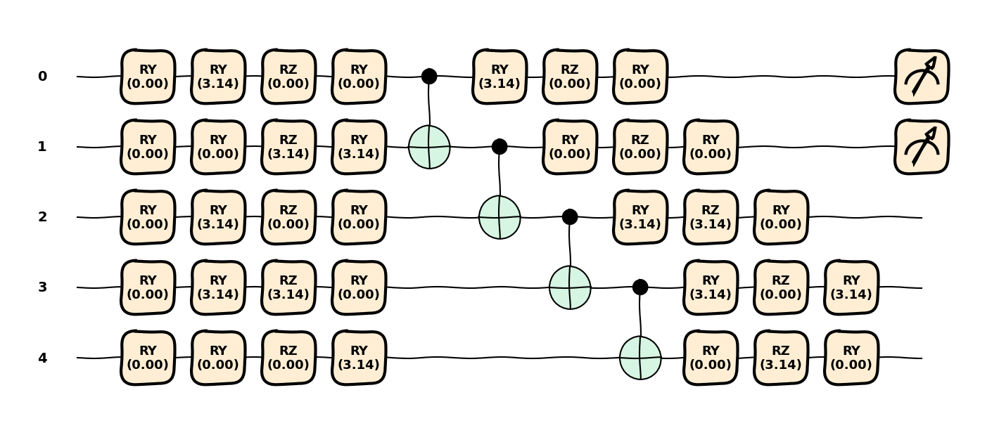

tensor([1.0000e+00, 1.0000e-12, 1.0000e-12, 1.0000e-12], grad_fn=<CopySlices>)
- Starting sampling for n_qubits: 4
- Starting sampling for n_qubits: 6
- Starting sampling for n_qubits: 8
- Starting sampling for n_qubits: 10
- Starting sampling for n_qubits: 12
- Starting sampling for n_qubits: 14
- Starting sampling for n_qubits: 16


In [ ]:
#action_set = [2]

#variances_action = [] 

#for n_actions in action_set:
#   print("Running variance for n_actions = ", n_actions)
fm_config = {
    "features": 4,
    "rotations": "Y",
}

ansatz_config = {
    "n_layers": lambda n: 2, 
    "rotations" : "YZY", #lambda n: ["Y {}".format(i) for i in range(n)],# + ["ZZ {} {}".format(i,i+1) for i in range(0,n-1,2)] + ["ZZ {} {}".format(i,i+1) for i in range(1,n-1,2)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain",
    "include_final_imprimitive": False,
    "include_feature_map_first": True,
    "include_hadamards_initial": False
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "discrete_0_pi_over_2",
    "policy": "hidden-like",
    "device": "lightning.qubit",
    "pp_truncation": 8,
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    "measurement_qubits": [0,1], #lambda n: [i for i in range(int(np.log2(n)))],
    #"shots": 10000,
    "parity_cnot_decomposition": False,
}

#normally distributed N(0,1) single point with four features
o = torch.tensor(np.random.normal(0,1,4), dtype=torch.float32)
o = torch.zeros(4)
print("Observation ", o)

ansatz_config["n_layers"] = 2
#ansatz_config["imprimitive_pattern"] = [(i,i+1) for i in range(0,3,2)] + [(i,i+1) for i in range(1,3,2)]
#ansatz_config["rotations"] = ["Y {}".format(i) for i in range(16)]
policy_model_config["measurement_qubits"] = [0,1]
policy = create_model("PQCBorn", policy_model_config, n_qubits=5)
draw_model(model=policy,policy_class="PQCBorn", n_qubits=5, num_inputs=4, inputs=torch.zeros(4))
plt.show()
print(policy.forward(o))
#print(policy.qlayer.params.data) 
#print(policy.qlayer.input_scaling_params.data) 

variance_qubit = policy_variance(policy_class="PQCBorn", 
                        policy_config_kwargs=policy_model_config,
                        n_samples=2000,
                        action=0,
                        qubit_list=[4,6,8,10,12,14,16],
                        parallel=True,
                        state=o)
#variances_action.append(variance_qubit[0])

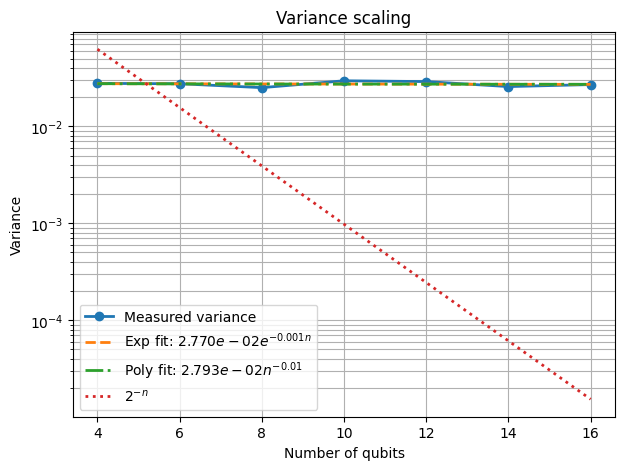

Exponential fit : y = 2.769657e-02 exp(-0.001361 n)
Polynomial fit : y = 2.793331e-02 n^(-0.010017)
R² exponential = 0.010000
R² polynomial  = 0.007042

>> Exponential fit is better.


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Data
qubit_list = np.array([4,6,8,10,12,14,16], dtype=float)
variance = np.array(variance_qubit[0], dtype=float)

# ------------------------------------------------------------------
# Exponential fit: y = A exp(-b n)
# ------------------------------------------------------------------
coef_exp = np.polyfit(qubit_list, np.log(variance), 1)
b = -coef_exp[0]
A = np.exp(coef_exp[1])

exp_fit = A * np.exp(-b * qubit_list)

# R² in log-space
logy = np.log(variance)
logy_exp = np.log(exp_fit)
ss_res_exp = np.sum((logy - logy_exp)**2)
ss_tot = np.sum((logy - np.mean(logy))**2)
r2_exp = 1 - ss_res_exp / ss_tot

# ------------------------------------------------------------------
# Polynomial fit: y = C n^{-p}
# ------------------------------------------------------------------
coef_poly = np.polyfit(np.log(qubit_list), np.log(variance), 1)
p = -coef_poly[0]
C = np.exp(coef_poly[1])

poly_fit = C * qubit_list**(-p)

# R² in log-space
logy_poly = np.log(poly_fit)
ss_res_poly = np.sum((logy - logy_poly)**2)
r2_poly = 1 - ss_res_poly / ss_tot

# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------
plt.figure(figsize=(7,5))

plt.plot(
    qubit_list,
    variance,
    "o-",
    lw=2,
    label="Measured variance"
)

plt.plot(
    qubit_list,
    exp_fit,
    "--",
    lw=2,
    label=rf"Exp fit: ${A:.3e}e^{{-{b:.3f}n}}$"
)

plt.plot(
    qubit_list,
    poly_fit,
    "-.",
    lw=2,
    label=rf"Poly fit: ${C:.3e}n^{{-{p:.2f}}}$"
)

plt.plot(
    qubit_list,
    2.0**(-qubit_list),
    ":",
    lw=2,
    label=r"$2^{-n}$"
)

#plt.plot(qubit_list, 1/(5*np.sqrt(np.pi*qubit_list)), ":", lw=2, label=r"$1/\sqrt{n}$")
plt.yscale("log")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")
plt.title("Variance scaling")

plt.grid(True, which="both")

plt.legend()

plt.show()

print(f"Exponential fit : y = {A:.6e} exp(-{b:.6f} n)")
print(f"Polynomial fit : y = {C:.6e} n^(-{p:.6f})")
print(f"R² exponential = {r2_exp:.6f}")
print(f"R² polynomial  = {r2_poly:.6f}")

if r2_exp > r2_poly:
    print("\n>> Exponential fit is better.")
else:
    print("\n>> Polynomial fit is better.")

Observation  tensor([0., 0., 0., 0.])


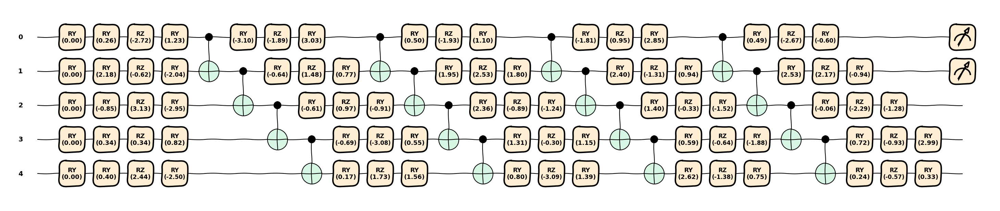

tensor([0.3126, 0.5887, 0.0171, 0.0816], grad_fn=<CopySlices>)


2026-07-23 20:07:52,460	INFO worker.py:1888 -- Started a local Ray instance.


- Starting sampling for n_qubits: 4
- Starting sampling for n_qubits: 6
- Starting sampling for n_qubits: 8
- Starting sampling for n_qubits: 10
- Starting sampling for n_qubits: 12
- Starting sampling for n_qubits: 14
- Starting sampling for n_qubits: 16


(raylet) [2026-07-24 10:13:26,565 E 65218 8753585] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-23_20-07-50_806465_63626 is over 95% full, available space: 15.9534 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-24 10:13:36,661 E 65218 8753585] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-23_20-07-50_806465_63626 is over 95% full, available space: 16.0109 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-24 10:13:46,706 E 65218 8753585] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-23_20-07-50_806465_63626 is over 95% full, available space: 18.0088 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


In [2]:
#action_set = [2]

#variances_action = [] 

#for n_actions in action_set:
#   print("Running variance for n_actions = ", n_actions)
fm_config = {
    "features": 4,
    "rotations": "Y",
}

ansatz_config = {
    "n_layers": lambda n: n, 
    "rotations" : "YZY", #lambda n: ["Y {}".format(i) for i in range(n)],# + ["ZZ {} {}".format(i,i+1) for i in range(0,n-1,2)] + ["ZZ {} {}".format(i,i+1) for i in range(1,n-1,2)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain",
    "include_final_imprimitive": False,
    "include_feature_map_first": True,
    "include_hadamards_initial": False
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "random_-pi_pi",
    "policy": "hidden-like",
    "device": "lightning.qubit",
    "pp_truncation": 8,
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    "measurement_qubits": [0,1], #lambda n: [i for i in range(int(np.log2(n)))],
    #"shots": 10000,
    "parity_cnot_decomposition": False,
}

#normally distributed N(0,1) single point with four features
o = torch.tensor(np.random.normal(0,1,4), dtype=torch.float32)
o = torch.zeros(4)
print("Observation ", o)

ansatz_config["n_layers"] = 5
#ansatz_config["imprimitive_pattern"] = [(i,i+1) for i in range(0,3,2)] + [(i,i+1) for i in range(1,3,2)]
#ansatz_config["rotations"] = ["Y {}".format(i) for i in range(16)]
policy_model_config["measurement_qubits"] = [0,1]
policy = create_model("PQCBorn", policy_model_config, n_qubits=5)
draw_model(model=policy,policy_class="PQCBorn", n_qubits=5, num_inputs=4, inputs=torch.zeros(4))
plt.show()
print(policy.forward(o))
ansatz_config["n_layers"] = lambda n: n

#print(policy.qlayer.params.data) 
#print(policy.qlayer.input_scaling_params.data) 

variance_qubit = policy_variance(policy_class="PQCBorn", 
                        policy_config_kwargs=policy_model_config,
                        n_samples=2000,
                        action=0,
                        qubit_list=[4,6,8,10,12,14,16],
                        parallel=True,
                        state=o)
#variances_action.append(variance_qubit[0])

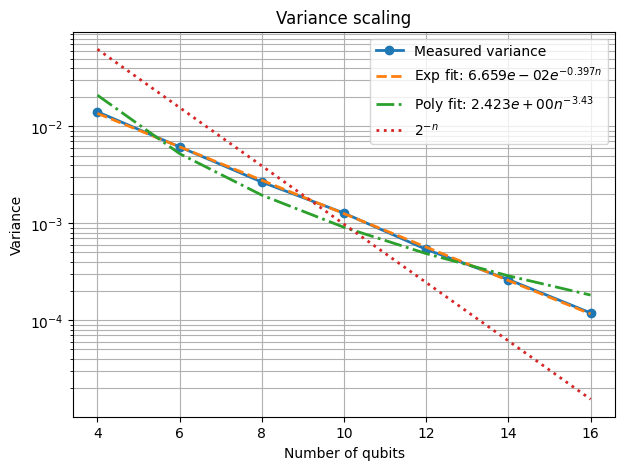

Exponential fit : y = 6.659063e-02 exp(-0.397181 n)
Polynomial fit : y = 2.423439e+00 n^(-3.426576)
R² exponential = 0.999575
R² polynomial  = 0.966623

>> Exponential fit is better.


In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Data
qubit_list = np.array([4,6,8,10,12,14,16], dtype=float)
variance = np.array(variance_qubit[0], dtype=float)

# ------------------------------------------------------------------
# Exponential fit: y = A exp(-b n)
# ------------------------------------------------------------------
coef_exp = np.polyfit(qubit_list, np.log(variance), 1)
b = -coef_exp[0]
A = np.exp(coef_exp[1])

exp_fit = A * np.exp(-b * qubit_list)

# R² in log-space
logy = np.log(variance)
logy_exp = np.log(exp_fit)
ss_res_exp = np.sum((logy - logy_exp)**2)
ss_tot = np.sum((logy - np.mean(logy))**2)
r2_exp = 1 - ss_res_exp / ss_tot

# ------------------------------------------------------------------
# Polynomial fit: y = C n^{-p}
# ------------------------------------------------------------------
coef_poly = np.polyfit(np.log(qubit_list), np.log(variance), 1)
p = -coef_poly[0]
C = np.exp(coef_poly[1])

poly_fit = C * qubit_list**(-p)

# R² in log-space
logy_poly = np.log(poly_fit)
ss_res_poly = np.sum((logy - logy_poly)**2)
r2_poly = 1 - ss_res_poly / ss_tot

# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------
plt.figure(figsize=(7,5))

plt.plot(
    qubit_list,
    variance,
    "o-",
    lw=2,
    label="Measured variance"
)

plt.plot(
    qubit_list,
    exp_fit,
    "--",
    lw=2,
    label=rf"Exp fit: ${A:.3e}e^{{-{b:.3f}n}}$"
)

plt.plot(
    qubit_list,
    poly_fit,
    "-.",
    lw=2,
    label=rf"Poly fit: ${C:.3e}n^{{-{p:.2f}}}$"
)

plt.plot(
    qubit_list,
    2.0**(-qubit_list),
    ":",
    lw=2,
    label=r"$2^{-n}$"
)

#plt.plot(qubit_list, 1/(5*np.sqrt(np.pi*qubit_list)), ":", lw=2, label=r"$1/\sqrt{n}$")
plt.yscale("log")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")
plt.title("Variance scaling")

plt.grid(True, which="both")

plt.legend()

plt.show()

print(f"Exponential fit : y = {A:.6e} exp(-{b:.6f} n)")
print(f"Polynomial fit : y = {C:.6e} n^(-{p:.6f})")
print(f"R² exponential = {r2_exp:.6f}")
print(f"R² polynomial  = {r2_poly:.6f}")

if r2_exp > r2_poly:
    print("\n>> Exponential fit is better.")
else:
    print("\n>> Polynomial fit is better.")

Observation  tensor([0., 0., 0., 0.])


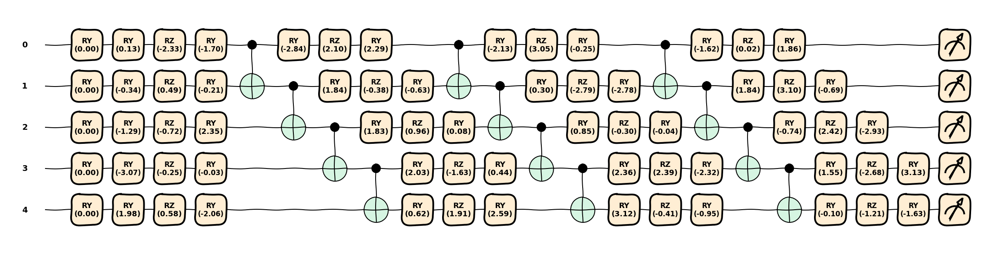

tensor([0.2232, 0.3513, 0.4255], grad_fn=<StackBackward0>)
- Starting sampling for n_qubits: 4
- Starting sampling for n_qubits: 6
- Starting sampling for n_qubits: 8
- Starting sampling for n_qubits: 10
- Starting sampling for n_qubits: 12
- Starting sampling for n_qubits: 14
- Starting sampling for n_qubits: 16


In [8]:
#action_set = [2]

#variances_action = [] 

#for n_actions in action_set:
#   print("Running variance for n_actions = ", n_actions)
fm_config = {
    "features": 4,
    "rotations": "Y",
}

ansatz_config = {
    "n_layers": 4, 
    "rotations" : "YZY", #lambda n: ["Y {}".format(i) for i in range(n)],# + ["ZZ {} {}".format(i,i+1) for i in range(0,n-1,2)] + ["ZZ {} {}".format(i,i+1) for i in range(1,n-1,2)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain",
    "include_final_imprimitive": False,
    "include_feature_map_first": True,
    "include_hadamards_initial": False
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 3,
    "init": "random_-pi_pi",
    "policy": "contiguous-like",
    "device": "lightning.qubit",
    "pp_truncation": 8,
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    "measurement_qubits": lambda n: list(range(n)),
    #"shots": 10000,
    "parity_cnot_decomposition": False,
}

#normally distributed N(0,1) single point with four features
o = torch.tensor(np.random.normal(0,1,4), dtype=torch.float32)
o = torch.zeros(4)
print("Observation ", o)

#ansatz_config["imprimitive_pattern"] = [(i,i+1) for i in range(0,3,2)] + [(i,i+1) for i in range(1,3,2)]
#ansatz_config["rotations"] = ["Y {}".format(i) for i in range(16)]
policy_model_config["measurement_qubits"] = [0,1,2,3,4]
policy = create_model("PQCBorn", policy_model_config, n_qubits=5)
draw_model(model=policy,policy_class="PQCBorn", n_qubits=5, num_inputs=4, inputs=torch.zeros(4))
plt.show()
policy_model_config["measurement_qubits"] = lambda n: list(range(n))

print(policy.forward(o))

#print(policy.qlayer.params.data) 
#print(policy.qlayer.input_scaling_params.data) 

variance_qubit = policy_variance(policy_class="PQCBorn", 
                        policy_config_kwargs=policy_model_config,
                        n_samples=2000,
                        action=0,
                        qubit_list=[4,6,8,10,12,14,16],
                        parallel=True,
                        state=o)
#variances_action.append(variance_qubit[0])

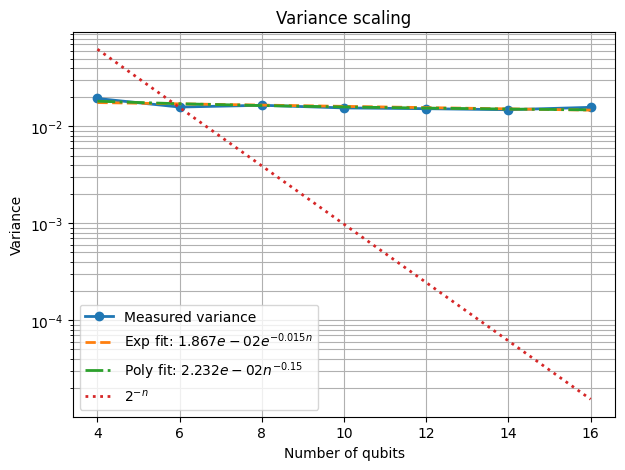

Exponential fit : y = 1.867125e-02 exp(-0.014953 n)
Polynomial fit : y = 2.232151e-02 n^(-0.148588)
R² exponential = 0.530913
R² polynomial  = 0.681133

>> Polynomial fit is better.


In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Data
qubit_list = np.array([4,6,8,10,12,14,16], dtype=float)
variance = np.array(variance_qubit[0], dtype=float)

# ------------------------------------------------------------------
# Exponential fit: y = A exp(-b n)
# ------------------------------------------------------------------
coef_exp = np.polyfit(qubit_list, np.log(variance), 1)
b = -coef_exp[0]
A = np.exp(coef_exp[1])

exp_fit = A * np.exp(-b * qubit_list)

# R² in log-space
logy = np.log(variance)
logy_exp = np.log(exp_fit)
ss_res_exp = np.sum((logy - logy_exp)**2)
ss_tot = np.sum((logy - np.mean(logy))**2)
r2_exp = 1 - ss_res_exp / ss_tot

# ------------------------------------------------------------------
# Polynomial fit: y = C n^{-p}
# ------------------------------------------------------------------
coef_poly = np.polyfit(np.log(qubit_list), np.log(variance), 1)
p = -coef_poly[0]
C = np.exp(coef_poly[1])

poly_fit = C * qubit_list**(-p)

# R² in log-space
logy_poly = np.log(poly_fit)
ss_res_poly = np.sum((logy - logy_poly)**2)
r2_poly = 1 - ss_res_poly / ss_tot

# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------
plt.figure(figsize=(7,5))

plt.plot(
    qubit_list,
    variance,
    "o-",
    lw=2,
    label="Measured variance"
)

plt.plot(
    qubit_list,
    exp_fit,
    "--",
    lw=2,
    label=rf"Exp fit: ${A:.3e}e^{{-{b:.3f}n}}$"
)

plt.plot(
    qubit_list,
    poly_fit,
    "-.",
    lw=2,
    label=rf"Poly fit: ${C:.3e}n^{{-{p:.2f}}}$"
)

plt.plot(
    qubit_list,
    2.0**(-qubit_list),
    ":",
    lw=2,
    label=r"$2^{-n}$"
)

#plt.plot(qubit_list, 1/(5*np.sqrt(np.pi*qubit_list)), ":", lw=2, label=r"$1/\sqrt{n}$")
plt.yscale("log")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")
plt.title("Variance scaling")

plt.grid(True, which="both")

plt.legend()

plt.show()

print(f"Exponential fit : y = {A:.6e} exp(-{b:.6f} n)")
print(f"Polynomial fit : y = {C:.6e} n^(-{p:.6f})")
print(f"R² exponential = {r2_exp:.6f}")
print(f"R² polynomial  = {r2_poly:.6f}")

if r2_exp > r2_poly:
    print("\n>> Exponential fit is better.")
else:
    print("\n>> Polynomial fit is better.")

Observation  tensor([0., 0., 0., 0.])


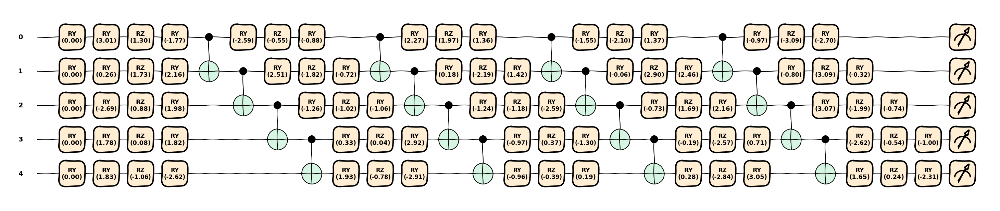

tensor([0.3486, 0.4802, 0.1713], grad_fn=<StackBackward0>)
- Starting sampling for n_qubits: 4
- Starting sampling for n_qubits: 6
- Starting sampling for n_qubits: 8
- Starting sampling for n_qubits: 10
- Starting sampling for n_qubits: 12
- Starting sampling for n_qubits: 14
- Starting sampling for n_qubits: 16


In [11]:
#action_set = [2]

#variances_action = [] 

#for n_actions in action_set:
#   print("Running variance for n_actions = ", n_actions)
fm_config = {
    "features": 4,
    "rotations": "Y",
}

ansatz_config = {
    "n_layers": lambda n: n, 
    "rotations" : "YZY", #lambda n: ["Y {}".format(i) for i in range(n)],# + ["ZZ {} {}".format(i,i+1) for i in range(0,n-1,2)] + ["ZZ {} {}".format(i,i+1) for i in range(1,n-1,2)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain",
    "include_final_imprimitive": False,
    "include_feature_map_first": True,
    "include_hadamards_initial": False
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 3,
    "init": "random_-pi_pi",
    "policy": "contiguous-like",
    "device": "lightning.qubit",
    "pp_truncation": 8,
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    "measurement_qubits": lambda n: list(range(n)),
    #"shots": 10000,
    "parity_cnot_decomposition": False,
}

#normally distributed N(0,1) single point with four features
o = torch.tensor(np.random.normal(0,1,4), dtype=torch.float32)
o = torch.zeros(4)
print("Observation ", o)

#ansatz_config["imprimitive_pattern"] = [(i,i+1) for i in range(0,3,2)] + [(i,i+1) for i in range(1,3,2)]
#ansatz_config["rotations"] = ["Y {}".format(i) for i in range(16)]
policy_model_config["measurement_qubits"] = [0,1,2,3,4]
ansatz_config["n_layers"] = 5
policy = create_model("PQCBorn", policy_model_config, n_qubits=5)
draw_model(model=policy,policy_class="PQCBorn", n_qubits=5, num_inputs=4, inputs=torch.zeros(4))
plt.show()
policy_model_config["measurement_qubits"] = lambda n: list(range(n))
ansatz_config["n_layers"] = lambda n: n

print(policy.forward(o))

#print(policy.qlayer.params.data) 
#print(policy.qlayer.input_scaling_params.data) 

variance_qubit = policy_variance(policy_class="PQCBorn", 
                        policy_config_kwargs=policy_model_config,
                        n_samples=2000,
                        action=0,
                        qubit_list=[4,6,8,10,12,14,16],
                        parallel=True,
                        state=o)
#variances_action.append(variance_qubit[0])

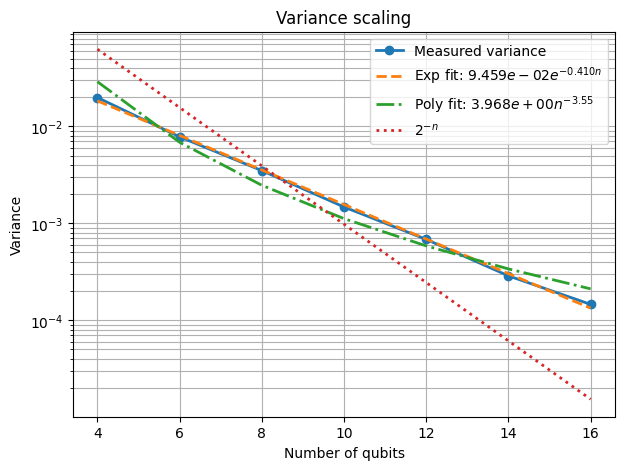

Exponential fit : y = 9.459068e-02 exp(-0.410484 n)
Polynomial fit : y = 3.967530e+00 n^(-3.551112)
R² exponential = 0.998834
R² polynomial  = 0.971244

>> Exponential fit is better.


In [12]:
import numpy as np
import matplotlib.pyplot as plt

# Data
qubit_list = np.array([4,6,8,10,12,14,16], dtype=float)
variance = np.array(variance_qubit[0], dtype=float)

# ------------------------------------------------------------------
# Exponential fit: y = A exp(-b n)
# ------------------------------------------------------------------
coef_exp = np.polyfit(qubit_list, np.log(variance), 1)
b = -coef_exp[0]
A = np.exp(coef_exp[1])

exp_fit = A * np.exp(-b * qubit_list)

# R² in log-space
logy = np.log(variance)
logy_exp = np.log(exp_fit)
ss_res_exp = np.sum((logy - logy_exp)**2)
ss_tot = np.sum((logy - np.mean(logy))**2)
r2_exp = 1 - ss_res_exp / ss_tot

# ------------------------------------------------------------------
# Polynomial fit: y = C n^{-p}
# ------------------------------------------------------------------
coef_poly = np.polyfit(np.log(qubit_list), np.log(variance), 1)
p = -coef_poly[0]
C = np.exp(coef_poly[1])

poly_fit = C * qubit_list**(-p)

# R² in log-space
logy_poly = np.log(poly_fit)
ss_res_poly = np.sum((logy - logy_poly)**2)
r2_poly = 1 - ss_res_poly / ss_tot

# ------------------------------------------------------------------
# Plot
# ------------------------------------------------------------------
plt.figure(figsize=(7,5))

plt.plot(
    qubit_list,
    variance,
    "o-",
    lw=2,
    label="Measured variance"
)

plt.plot(
    qubit_list,
    exp_fit,
    "--",
    lw=2,
    label=rf"Exp fit: ${A:.3e}e^{{-{b:.3f}n}}$"
)

plt.plot(
    qubit_list,
    poly_fit,
    "-.",
    lw=2,
    label=rf"Poly fit: ${C:.3e}n^{{-{p:.2f}}}$"
)

plt.plot(
    qubit_list,
    2.0**(-qubit_list),
    ":",
    lw=2,
    label=r"$2^{-n}$"
)

#plt.plot(qubit_list, 1/(5*np.sqrt(np.pi*qubit_list)), ":", lw=2, label=r"$1/\sqrt{n}$")
plt.yscale("log")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")
plt.title("Variance scaling")

plt.grid(True, which="both")

plt.legend()

plt.show()

print(f"Exponential fit : y = {A:.6e} exp(-{b:.6f} n)")
print(f"Polynomial fit : y = {C:.6e} n^(-{p:.6f})")
print(f"R² exponential = {r2_exp:.6f}")
print(f"R² polynomial  = {r2_poly:.6f}")

if r2_exp > r2_poly:
    print("\n>> Exponential fit is better.")
else:
    print("\n>> Polynomial fit is better.")

In [16]:
print(variance_qubit[0])

[np.float64(0.035793180088676484), np.float64(0.021375073030610196), np.float64(0.013321755428873271), np.float64(0.008342438709191234), np.float64(0.005578255624299388), np.float64(0.0038870112396059055), np.float64(0.00270059799351296)]


In [101]:
n_qubits = 25

dev = qml.device("lightning.qubit" , wires=n_qubits, batch_obs=True)


def qc(params,layers):
    for l in range(layers):
        for i in range(n_qubits):
            qml.RY(params[l][i], wires=i)
        if l < layers - 1:
            for i in range(n_qubits-1):
                qml.CZ(wires=[i, i+1])

    observable = tuple(qml.expval(qml.Projector([0,0], wires=[i,i+1])) for i in range(n_qubits-1))
    return observable

qc = qml.qnode(dev)(qc)

def qc_hamiltonian(params,layers):
    for l in range(layers):
        for i in range(n_qubits):
            qml.RY(params[l][i], wires=i)
        if l < layers - 1:
            for i in range(n_qubits-1):
                qml.CZ(wires=[i, i+1])

    #return the expectation value of the pennylane Hamiltonian H = 1/|projectors| sum_{i=0}^{n_qubits-2} |00><00|_{i,i+1}
    H = qml.Hamiltonian([1/(n_qubits-1)]*(n_qubits-1), [qml.Projector([0,0], wires=[i,i+1]) for i in range(n_qubits-1)])
    return qml.expval(H)

qc_hamiltonian = qml.qnode(dev)(qc_hamiltonian)


In [102]:
layers = 25
params = torch.randn((layers,n_qubits))

In [103]:

torch.tensor(qc(params=params, layers=layers)).mean()

tensor(0.2544, dtype=torch.float64)

In [104]:
qc_hamiltonian(params=params, layers=layers)

tensor(0.2544)

In [4]:
n_qubits = 5

dev = qml.device("default.clifford", wires=n_qubits)

def qc(inputs=None, params=None):
    qml.Hadamard(wires=0)
    qml.Hadamard(wires=1)

    # Use the TorchLayer parameter
    qml.RZ(params[0], wires=1)

    return tuple(qml.expval(qml.PauliZ(i)) for i in range(1))

qnode = qml.QNode(qc, dev)

qcc = qml.transforms.clifford_t_decomposition(qnode)

tl = qml.qnn.TorchLayer(
    qcc,
    weight_shapes={"params": (1,)},
    init_method=lambda tensor: torch.nn.init.constant_(tensor, np.pi),
)

print(tl(torch.tensor([0.0])))

tensor([0.], grad_fn=<ToCopyBackward0>)


In [1]:
import qasp
from qasp import * 
import matplotlib.pyplot as plt
import torch
from pennylane import numpy as np

In [4]:
n_qubits = 5
globalz = ("Z"*n_qubits + " {}"*n_qubits).format(*range(n_qubits))

globalz

'ZZZZZ 0 1 2 3 4'

#### |A| = 2 -> GLOBAL Z , GLOBAL Z-1 

In [ ]:
qubit_list = [4,6,8,10,12,14,16]
#normally distributed single point with four features
o = torch.randn(4,)

fm_config = {
    "features": 4,
    "rotations": "Z",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 2,
    "rotations" : "ZY", #["ZZ {} {}".format(i,(i+1)%n_qubits) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain",
    "include_final_imprimitive": True,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}
policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2 ,
    "init": "discrete_0_pi_over_2",
    "device": "lightning.qubit",
    "diff_method": "adjoint",
    "observables": lambda n: [("Z"*n + " {}"*n).format(*range(n)) , ("Z"*(n-1) + " {}"*(n-1)).format(*range(n-1))],
    "fc_layer": True,
}

variances = policy_variance(policy_class="PQCSoftmax", 
                        policy_config_kwargs=policy_model_config_softmax,
                        n_samples=2000,
                        #action=0,
                        qubit_list=qubit_list,
                        parallel=True,
                        state=o)


2026-07-30 10:44:14,114	INFO worker.py:1888 -- Started a local Ray instance.


- Starting sampling for n_qubits: 4


(raylet) [2026-07-30 10:44:23,017 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 14.412 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 10:44:33,048 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 14.4118 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


- Starting sampling for n_qubits: 6
- Starting sampling for n_qubits: 8


(raylet) [2026-07-30 10:44:43,053 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 14.4117 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 10:44:53,088 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 14.4117 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


- Starting sampling for n_qubits: 10


... (4 outputs left out)

(raylet) [2026-07-30 10:45:33,243 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 14.4103 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 10:45:43,264 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 13.4093 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 10:45:53,295 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 13.4093 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


- Starting sampling for n_qubits: 16


(raylet) [2026-07-30 10:46:03,339 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 13.4091 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 10:46:13,362 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 13.4091 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 10:46:23,402 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 13.4089 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 10:46:33,413 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 13.4085 GB; capacity: 421.525 GB. Object creation

(raylet) [2026-07-30 10:48:03,742 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 13.4201 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 10:48:13,769 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 13.4201 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 10:48:23,855 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 13.4201 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 10:48:33,952 E 36255 16826729] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_10-44-10_457113_54231 is over 95% full, available space: 13.4192 GB; capacity: 421.525 GB. Object creation

([np.float64(0.007192873491319138), np.float64(0.001140693079938365), np.float64(0.00019840181390183995), np.float64(1.798294467226059e-06), np.float64(1.7772450169299935e-18), np.float64(0.0), np.float64(0.0)], {4: [0.5, 0.5, 0.5000000596046448, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5000000596046448, 0.5, 0.5, 0.5, 0.5, 0.5, 0.35965824127197266, 0.5, 0.5, 0.7039432525634766, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.8747996687889099, 0.8572325706481934, 0.6533142328262329, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5000000596046448, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.4999999701976776, 0.5, 0.5, 0.8778452277183533, 0.5, 0.5, 0.5, 0.8036572933197021, 0.5, 0.5, 0.5, 0.7382085919380188, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.8807970285415649, 0.5, 0.5, 0.5, 0.5, 0.3862503170967102, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5000000596046448, 0.677996039390564, 0.8807970285415649, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5, 0.5000000596046448, 0.5, 0.5, 0.5, 0.5, 0.1

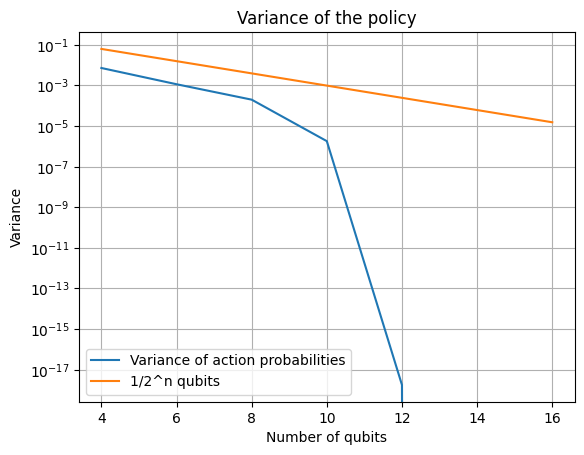

In [ ]:
import matplotlib.pyplot as plt

qubit_list = [4,6,8,10,12,14,16]
print(variances)
plt.plot(qubit_list, variances[0], label="Variance of action probabilities")
plt.plot(qubit_list ,[2**(-i) for i in qubit_list], label="1/2^n qubits")
#plt.plot(qubit_list, [(1/16)*((0.25**i) + 0.25**(i-1) + 0.25) for i in qubit_list], label="theory LB")
#plt.plot(qubit_list, [(1/16)*((0.5**i) + 0.5**(i-1) + 0.5) for i in qubit_list], label="theory UP")
#plt.plot(qubit_list, [(1/4)*(0.5**(i/2)) for i in qubit_list], label="theory exp")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")

plt.yscale("log")

plt.title("Variance of the policy")
plt.grid()


plt.legend()

#plot with 300 dpi 
plt.rcParams['figure.dpi'] = 300

plt.show()

#### |A|=2 -> GLOBAL Z , LOCAL Z_2 with w ~ Unif({-1,1})

In [ ]:
qubit_list = [4,6,8,10,12,14,16]
#normally distributed single point with four features
o = torch.randn(4,)

fm_config = {
    "features": 4,
    "rotations": "Z",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 2,
    "rotations" : "ZY", #["ZZ {} {}".format(i,(i+1)%n_qubits) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain",
    "include_final_imprimitive": True,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}
policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2 ,
    "init": "random_-pi_pi",
    "device": "lightning.qubit",
    "diff_method": "adjoint",
    "observables": lambda n: ["Z 2" , ("Z"*n + " {}"*n).format(*range(n))],
    "fc_layer": True,
}

variances = policy_variance(policy_class="PQCSoftmax", 
                        policy_config_kwargs=policy_model_config_softmax,
                        n_samples=2000,
                        #action=0,
                        qubit_list=qubit_list,
                        parallel=True,
                        state=o)


2026-07-30 12:59:14,478	INFO worker.py:1888 -- Started a local Ray instance.


- Starting sampling for n_qubits: 4


(raylet) [2026-07-30 12:59:24,482 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 15.16 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 12:59:34,569 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 15.1578 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


- Starting sampling for n_qubits: 6


(raylet) [2026-07-30 12:59:44,629 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 15.1567 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


- Starting sampling for n_qubits: 8


... (6 outputs left out)

(raylet) [2026-07-30 13:00:45,064 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 15.1396 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 13:00:55,186 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 15.1379 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 13:01:05,265 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 14.1362 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 13:01:15,300 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 14.1399 GB; capacity: 421.525 GB. Object creation

- Starting sampling for n_qubits: 16


(raylet) [2026-07-30 13:01:45,431 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 14.1349 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 13:01:55,505 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 14.1348 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 13:02:05,517 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 14.1328 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 13:02:15,554 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 14.1329 GB; capacity: 421.525 GB. Object creation

(raylet) [2026-07-30 13:04:16,229 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 14.1404 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 13:04:26,318 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 14.1392 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 13:04:36,318 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 14.1401 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 13:04:46,335 E 52771 17197567] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-59-12_849467_52234 is over 95% full, available space: 14.138 GB; capacity: 421.525 GB. Object creation 

([np.float64(0.01094218037280311), np.float64(0.00728515598215682), np.float64(0.006241566872397359), np.float64(0.005986135626762848), np.float64(0.0063997980517671955), np.float64(0.006040186194122015), np.float64(0.006294466118023176)], {4: [0.5, 0.505912184715271, 0.4797203242778778, 0.6618821024894714, 0.7408715486526489, 0.7525511980056763, 0.5035372972488403, 0.551026463508606, 0.5, 0.541786253452301, 0.7189356088638306, 0.7160605788230896, 0.4504941403865814, 0.488394558429718, 0.39049863815307617, 0.5250968933105469, 0.6025095582008362, 0.5049217343330383, 0.6154240965843201, 0.522648274898529, 0.537730872631073, 0.5777941942214966, 0.506942868232727, 0.580934464931488, 0.5702691078186035, 0.5, 0.6131735444068909, 0.4348571002483368, 0.39011940360069275, 0.46894851326942444, 0.5, 0.42122799158096313, 0.5, 0.5857228636741638, 0.5, 0.5031357407569885, 0.47978830337524414, 0.7683579921722412, 0.5, 0.5442177653312683, 0.6027178764343262, 0.5, 0.5005725622177124, 0.3847778737545013

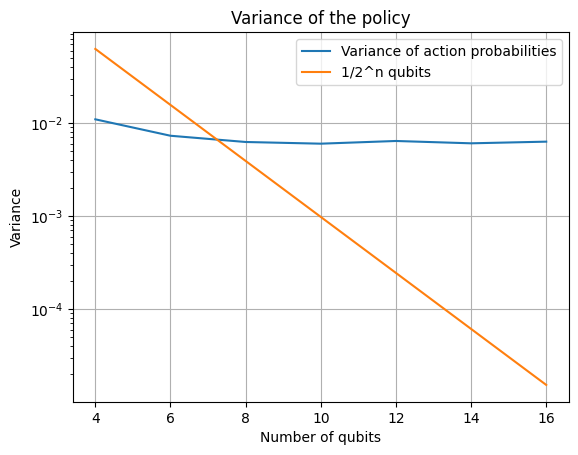

In [3]:
import matplotlib.pyplot as plt

qubit_list = [4,6,8,10,12,14,16]
print(variances)
plt.plot(qubit_list, variances[0], label="Variance of action probabilities")
plt.plot(qubit_list ,[2**(-i) for i in qubit_list], label="1/2^n qubits")
#plt.plot(qubit_list, [(1/16)*((0.25**i) + 0.25**(i-1) + 0.25) for i in qubit_list], label="theory LB")
#plt.plot(qubit_list, [(1/16)*((0.5**i) + 0.5**(i-1) + 0.5) for i in qubit_list], label="theory UP")
#plt.plot(qubit_list, [(1/4)*(0.5**(i/2)) for i in qubit_list], label="theory exp")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")

plt.yscale("log")

plt.title("Variance of the policy")
plt.grid()


plt.legend()

#plot with 300 dpi 
#plt.rcParams['figure.dpi'] = 300

plt.show()

#### |A|=2 -> GLOBAL Z , LOCAL Z_2 with w = 1/2^n 

In [2]:
qubit_list = [4,6,8,10,12,14,16]
#normally distributed single point with four features
o = torch.randn(4,)

fm_config = {
    "features": 4,
    "rotations": "Z",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 2,
    "rotations" : "ZY", #["ZZ {} {}".format(i,(i+1)%n_qubits) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain",
    "include_final_imprimitive": True,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}
policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2 ,
    "init": "random_-pi_pi",
    "device": "lightning.qubit",
    "diff_method": "adjoint",
    "observables": lambda n: ["Z 2" , ("Z"*n + " {}"*n).format(*range(n))],
    "fc_layer": True,
}

variances = policy_variance(policy_class="PQCSoftmax", 
                        policy_config_kwargs=policy_model_config_softmax,
                        n_samples=2000,
                        #action=0,
                        qubit_list=qubit_list,
                        parallel=True,
                        state=o)


2026-07-30 12:51:23,112	INFO worker.py:1888 -- Started a local Ray instance.


- Starting sampling for n_qubits: 4


(raylet) [2026-07-30 12:51:33,055 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 13.9 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


- Starting sampling for n_qubits: 6


(raylet) [2026-07-30 12:51:43,089 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 13.8998 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


- Starting sampling for n_qubits: 8


... (6 outputs left out)

(raylet) [2026-07-30 12:52:33,312 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 13.8991 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 12:52:43,385 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 13.8895 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 12:52:53,397 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 13.8854 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 12:53:03,488 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 13.8772 GB; capacity: 421.525 GB. Object creation

- Starting sampling for n_qubits: 16


(raylet) [2026-07-30 12:53:23,539 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 13.8894 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 12:53:33,573 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 13.887 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 12:53:43,633 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 13.8867 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 12:53:53,669 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 13.8849 GB; capacity: 421.525 GB. Object creation 

(raylet) [2026-07-30 12:55:44,104 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 15.0788 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 12:55:54,198 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 15.1383 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 12:56:04,273 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 15.1383 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-30 12:56:14,374 E 45318 17173196] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-30_12-51-21_433968_44827 is over 95% full, available space: 15.1383 GB; capacity: 421.525 GB. Object creation

([np.float64(4.97449898853728e-05), np.float64(1.7952318958008836e-06), np.float64(1.1432522699063484e-07), np.float64(6.50183970879361e-09), np.float64(4.4531746484597685e-10), np.float64(2.736242278394094e-11), np.float64(1.6090048186456493e-12)], {4: [0.5004798173904419, 0.48889589309692383, 0.49671944975852966, 0.4985124468803406, 0.5, 0.5059585571289062, 0.5, 0.5010225772857666, 0.5043366551399231, 0.5061697959899902, 0.49328359961509705, 0.5242615342140198, 0.5, 0.5018013119697571, 0.5, 0.4945739805698395, 0.5044329166412354, 0.5, 0.4963628947734833, 0.48454368114471436, 0.49816644191741943, 0.5, 0.49688974022865295, 0.5, 0.5181045532226562, 0.5028654932975769, 0.5, 0.500778317451477, 0.5, 0.491433322429657, 0.4958648681640625, 0.47767627239227295, 0.4979780316352844, 0.5037713050842285, 0.4965672791004181, 0.5076026320457458, 0.5005951523780823, 0.5070685744285583, 0.500341534614563, 0.49175816774368286, 0.5050773620605469, 0.48728448152542114, 0.4896507263183594, 0.500704646110

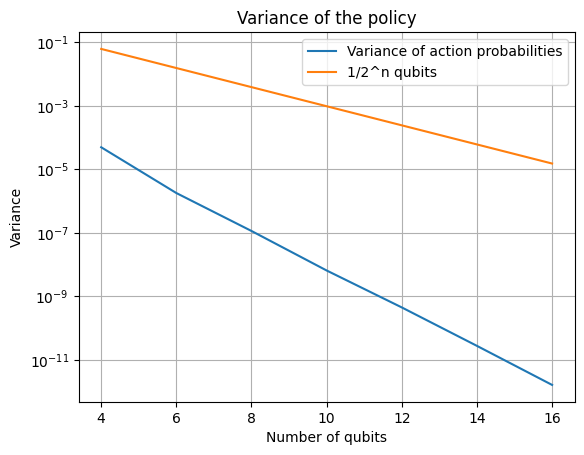

In [3]:
import matplotlib.pyplot as plt

qubit_list = [4,6,8,10,12,14,16]
print(variances)
plt.plot(qubit_list, variances[0], label="Variance of action probabilities")
plt.plot(qubit_list ,[2**(-i) for i in qubit_list], label="1/2^n qubits")
#plt.plot(qubit_list, [(1/16)*((0.25**i) + 0.25**(i-1) + 0.25) for i in qubit_list], label="theory LB")
#plt.plot(qubit_list, [(1/16)*((0.5**i) + 0.5**(i-1) + 0.5) for i in qubit_list], label="theory UP")
#plt.plot(qubit_list, [(1/4)*(0.5**(i/2)) for i in qubit_list], label="theory exp")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")

plt.yscale("log")

plt.title("Variance of the policy")
plt.grid()


plt.legend()

#plot with 300 dpi 
#plt.rcParams['figure.dpi'] = 300

plt.show()

#### |A|=2 -> GLOBAL Z , LOCAL Z_2 with w = 1/n 

In [ ]:
qubit_list = [4,6,8,10,12,14,16]
#normally distributed single point with four features
o = torch.randn(4,)

fm_config = {
    "features": 4,
    "rotations": "Z",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 2,
    "rotations" : "ZY", #["ZZ {} {}".format(i,(i+1)%n_qubits) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "chain",
    "include_final_imprimitive": True,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}
policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2 ,
    "init": "random_-pi_pi",
    "device": "lightning.qubit",
    "diff_method": "adjoint",
    "observables": lambda n: ["Z 2" , ("Z"*n + " {}"*n).format(*range(n))],
    "fc_layer": True,
}

variances = policy_variance(policy_class="PQCSoftmax", 
                        policy_config_kwargs=policy_model_config_softmax,
                        n_samples=2000,
                        #action=0,
                        qubit_list=qubit_list,
                        parallel=True,
                        state=o)


2026-07-31 12:18:21,301	INFO worker.py:1888 -- Started a local Ray instance.


- Starting sampling for n_qubits: 4


(raylet) [2026-07-31 12:18:31,225 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9405 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-31 12:18:41,288 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9389 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-31 12:18:51,311 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9431 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


- Starting sampling for n_qubits: 6


(raylet) [2026-07-31 12:19:01,388 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9416 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


- Starting sampling for n_qubits: 8


... (6 outputs left out)

(raylet) [2026-07-31 12:20:11,835 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.953 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-31 12:20:21,898 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9523 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-31 12:20:31,992 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9534 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.


- Starting sampling for n_qubits: 16


(raylet) [2026-07-31 12:20:42,082 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9512 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-31 12:20:52,170 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9502 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-31 12:21:02,238 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9479 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-31 12:21:12,276 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9477 GB; capacity: 421.525 GB. Object creation

(raylet) [2026-07-31 12:22:32,671 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9562 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-31 12:22:42,756 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.96 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-31 12:22:52,756 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9595 GB; capacity: 421.525 GB. Object creation will fail if spilling is required.
(raylet) [2026-07-31 12:23:02,835 E 54122 18709937] (raylet) file_system_monitor.cc:116: /tmp/ray/session_2026-07-31_12-18-19_866681_53504 is over 95% full, available space: 16.9559 GB; capacity: 421.525 GB. Object creation w

([np.float64(0.000817441322891027), np.float64(0.0002163974121544879), np.float64(0.00010827430107319048), np.float64(6.88689070358375e-05), np.float64(5.1885669989878405e-05), np.float64(3.872724194453676e-05), np.float64(2.6898696965221043e-05)], {4: [0.5397787094116211, 0.5, 0.4981435537338257, 0.5274133086204529, 0.4823465049266815, 0.4489828646183014, 0.488150030374527, 0.5, 0.5035684108734131, 0.5, 0.4476426839828491, 0.4569072127342224, 0.4947797954082489, 0.5439112782478333, 0.5, 0.5607773065567017, 0.4870036840438843, 0.49280115962028503, 0.4669710397720337, 0.4725944697856903, 0.5, 0.44218799471855164, 0.4978314936161041, 0.5, 0.46848544478416443, 0.5, 0.5010046362876892, 0.4658365845680237, 0.46243226528167725, 0.49888020753860474, 0.5188981890678406, 0.5262411832809448, 0.5, 0.5190951228141785, 0.49553632736206055, 0.45041775703430176, 0.43946167826652527, 0.5577657222747803, 0.5260518789291382, 0.6001800894737244, 0.5, 0.5, 0.5, 0.5348498225212097, 0.5, 0.4975249469280243,

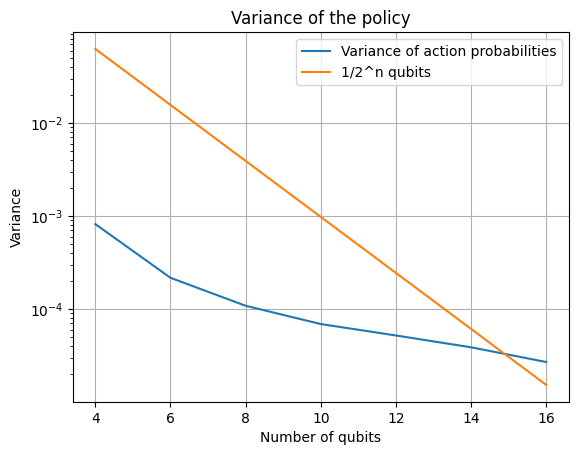

In [3]:
import matplotlib.pyplot as plt

qubit_list = [4,6,8,10,12,14,16]
print(variances)
plt.plot(qubit_list, variances[0], label="Variance of action probabilities")
plt.plot(qubit_list ,[2**(-i) for i in qubit_list], label="1/2^n qubits")
#plt.plot(qubit_list, [(1/16)*((0.25**i) + 0.25**(i-1) + 0.25) for i in qubit_list], label="theory LB")
#plt.plot(qubit_list, [(1/16)*((0.5**i) + 0.5**(i-1) + 0.5) for i in qubit_list], label="theory UP")
#plt.plot(qubit_list, [(1/4)*(0.5**(i/2)) for i in qubit_list], label="theory exp")

plt.xlabel("Number of qubits")
plt.ylabel("Variance")

plt.yscale("log")

plt.title("Variance of the policy")
plt.grid()


plt.legend()

#plot with 300 dpi 
#plt.rcParams['figure.dpi'] = 300

plt.show()

In [ ]:
n_qubits = 100

fm_config = {
    "features": 4,
    "rotations": "Z",
}

ansatz_config = {
    "n_layers": 3,
    "rotations": "ZY",
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True,
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.pp",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    "parity_cnot_decomposition": False,
    "pp_truncation": 5,  # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
}

policy = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)

#draw_model(model=policy, policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=4, inputs=torch.zeros(4))



In [5]:
state = torch.rand(4)


In [6]:
policy.forward(state)

tensor([0.2084, 0.2916, 0.2916, 0.2084], grad_fn=<ClampBackward1>)

In [ ]:
optimizer = torch.optim.Adam(policy.parameters(), lr=0.1)

steps = 500
for step in range(steps):
    action_probs = policy.forward(state)
    loss = -torch.log(action_probs[0])  # assuming action 0 is the optimal action for this state
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    print(f"Step {step+1}/{steps}, probs: {action_probs.detach().numpy()}")

Step 1/500, probs: [4.9997821e-01 2.1785498e-05 2.1785498e-05 4.9997821e-01]
Step 2/500, probs: [0.49549797 0.00450203 0.00450203 0.49549797]
Step 3/500, probs: [4.9969938e-01 3.0061603e-04 3.0061603e-04 4.9969938e-01]
Step 4/500, probs: [0.49901658 0.00098343 0.00098343 0.49901658]
Step 5/500, probs: [0.49742854 0.00257146 0.00257146 0.49742854]
Step 6/500, probs: [0.4981444  0.00185563 0.00185563 0.4981444 ]
Step 7/500, probs: [4.9953488e-01 4.6512485e-04 4.6512485e-04 4.9953488e-01]
Step 8/500, probs: [4.9996951e-01 3.0487776e-05 3.0487776e-05 4.9996951e-01]
Step 9/500, probs: [0.49933296 0.00066705 0.00066705 0.49933296]
Step 10/500, probs: [0.49873325 0.00126675 0.00126675 0.49873325]
Step 11/500, probs: [0.4988997 0.0011003 0.0011003 0.4988997]
Step 12/500, probs: [4.9952799e-01 4.7202408e-04 4.7202408e-04 4.9952799e-01]
Step 13/500, probs: [4.9995226e-01 4.7743320e-05 4.7743320e-05 4.9995226e-01]
Step 14/500, probs: [4.9985516e-01 1.4482439e-04 1.4482439e-04 4.9985516e-01]
Step 

Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x107507460>>
Traceback (most recent call last):
  File "/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 781, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


Step 155/500, probs: [5.0000000e-01 1.4901161e-08 1.4901161e-08 5.0000000e-01]
Step 156/500, probs: [5.e-01 1.e-12 1.e-12 5.e-01]
Step 157/500, probs: [5.e-01 1.e-12 1.e-12 5.e-01]
Step 158/500, probs: [5.e-01 1.e-12 1.e-12 5.e-01]
Step 159/500, probs: [5.e-01 1.e-12 1.e-12 5.e-01]
Step 160/500, probs: [5.0000000e-01 1.4901161e-08 1.4901161e-08 5.0000000e-01]
Step 161/500, probs: [5.e-01 1.e-12 1.e-12 5.e-01]
Step 162/500, probs: [5.e-01 1.e-12 1.e-12 5.e-01]
Step 163/500, probs: [5.e-01 1.e-12 1.e-12 5.e-01]
Step 164/500, probs: [5.e-01 1.e-12 1.e-12 5.e-01]


In [27]:
#print policy parameters 
print(policy.qlayer.state_dict())

OrderedDict([('input_scaling_params', tensor([ 2.0503e+00,  7.2477e-01, -4.2463e-02, -1.5953e-01,  8.5164e-01,
        -2.4123e-02,  5.5969e-01, -4.7882e-01,  8.8560e-02, -9.9105e-01,
        -1.7777e+00, -1.8913e-01,  2.5154e-01,  1.3384e+00, -6.9719e-01,
        -6.4260e-01,  2.7120e+00, -1.4610e+00,  7.9920e-02, -1.5390e+00,
        -7.1637e-01,  4.8519e-01, -1.2914e+00, -5.3616e-01,  1.6477e+00,
        -2.6020e+00, -1.6055e-01,  5.9245e-01, -6.4710e-01, -1.4792e+00,
         7.6054e-01, -9.8449e-01, -3.8223e-01, -1.6570e+00, -1.0066e+00,
         6.3890e-01, -6.7373e-01, -6.8559e-01,  8.4063e-01, -1.6342e+00,
        -3.5840e-01, -1.0565e+00,  6.3857e-01, -1.7425e+00,  1.8112e-01,
         1.4015e+00,  1.1404e+00,  3.5034e-01, -8.2734e-01,  2.4281e+00,
         6.9265e-01,  3.0664e-01,  4.6109e-01,  1.0267e-02,  4.4965e-01,
        -5.3243e-01, -6.1151e-01, -9.8323e-02, -5.2030e-01,  2.7741e-01,
         2.4321e-01, -1.8606e-01,  4.4031e-01, -2.1588e+00, -3.6653e-01,
        -1.28

In [28]:
n_qubits = 22

fm_config = {
    "features": 4,
    "rotations": "Z",
}

ansatz_config = {
    "n_layers": 3,
    "rotations": "ZY",
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True,
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    "parity_cnot_decomposition": False,
    "pp_truncation": 4,  # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
}

policy2 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)




In [29]:
policy2.qlayer.load_state_dict(policy.qlayer.state_dict())

policy2.forward(state)


tensor([0.2468, 0.2573, 0.2544, 0.2415], grad_fn=<CopySlices>)

In [24]:
#compare parameters of policy and policy2
for name, param in policy.qlayer.state_dict().items():
    print(name, torch.allclose(param, policy2.qlayer.state_dict()[name]))
    


input_scaling_params True
params True
